# 🚨 StintIQ — Model 4: Safety Car / VSC Probability (Discrete-Time Hazard)
*Applied Machine Learning in Formula 1 Motorsport Analytics*

---

## Executive Overview
Model 4 answers one question for the strategy layer: **"given the race state at the start of lap $t$, how likely is a Safety Car (SC) or Virtual Safety Car (VSC) to be deployed on this lap?"**

A neutralisation changes the value of a pit stop (the pit-lane loss shrinks while the field is slowed), so Model 3 (strategy optimiser) needs the **full hazard curve**, not one number. Model 4 therefore produces:

| Output | Used by |
|---|---|
| per-lap hazard $h_t$ with an uncertainty band | Model 3 Monte Carlo |
| cumulative probability $P(\text{event by lap } T)$ | Model 3 pit-window logic, Model 5 live features |
| sampled event timing, type (SC / VSC) and duration | Model 3 race simulator |
| a unified lap-status table (green / SC / VSC / red) | Model 1 cleaning filter |

**Design principles (from the StintIQ technical document, §3.4):** hazard formulation, calibration over accuracy, rare-event honesty, race-based validation, strict information boundary.

## 1. Theoretical Formulation

### 1.1 Discrete-time hazard
Let $T$ be the lap on which a *new* neutralisation starts. The hazard is

$$h_t = P(T = t \mid T \ge t,\; \mathbf{x}_t)$$

where $\mathbf{x}_t$ is everything known **at the start of lap $t$** (so only data from laps $\le t-1$). It is estimated as a logistic regression on a *person-period* table (one row per race-lap at risk):

$$\operatorname{logit}(h_t) = \alpha\big(\text{progress}_t\big) + \boldsymbol\beta^\top \mathbf{x}_t$$

with $\alpha(\cdot)$ a smooth baseline hazard over race progress (spline). Survival and cumulative probability follow directly:

$$S(t) = \prod_{s \le t} (1 - h_s), \qquad F(t) = 1 - S(t)$$

### 1.2 Label definitions (explicit, as required by the technical document)

| Term | Definition in this notebook |
|---|---|
| **Neutralised lap** | FastF1 `TrackStatus` contains `4` (SC) or `6`/`7` (VSC) for at least `STATUS_MIN_FRAC` of the cars on that lap |
| **Onset (event)** | first neutralised lap after a non-neutralised lap. SC→VSC or VSC→SC without a green lap in between is *one* episode |
| **At-risk lap** | previous lap was *not* neutralised and the current lap is not a red-flag lap |
| **Label** $y_t$ | `1` if a new episode starts on lap $t$, else `0` |
| **Red flag** | excluded from the risk set; not modelled here |

### 1.3 Why the *opposite* cleaning rule to Model 1
Model 1 **throws away** non-green laps (`TrackStatus == '1'` filter). Model 4 **needs** them: they are the labels. Both notebooks read the same `lap_data_raw.csv` and the same `EventName` / `LapNumber` keys, and Section 10 exports a lap-status table so Model 1's filter can reuse Model 4's definition.

In [4]:
# ==============================================================================
# 2. Environment Setup & Dependency Loading
# ==============================================================================
import os, sys, json, time, math, warnings, importlib
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, roc_auc_score
import joblib

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("[INFO] xgboost not found (optional): pip install xgboost")
try:
    import catboost as cb
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("[INFO] catboost not found (optional): pip install catboost")

# Same plotting conventions as Model 1
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8, 'figure.dpi': 110,
                     'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 9.5})

PAL = dict(coral='#E8604C', amber='#F5A623', teal='#1ABC9C', purple='#8E44AD',
           blue='#2980B9', grey='#7F8C8D', green='#27AE60', ink='#2C3E50', red='#B03A2E')

# Keep everything beside the notebook, like Model 1
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'Model1_LapTime.ipynb').exists() or (p / 'Model4_SC_VSC.ipynb').exists()),
                    Path.cwd())
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)            # so the %%writefile module below lands next to the notebooks

RANDOM_STATE = 42
rng_global = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
print(f"StintIQ Model 4 environment loaded. PROJECT_ROOT = {PROJECT_ROOT}")

StintIQ Model 4 environment loaded. PROJECT_ROOT = /Users/hemant/Work/StintIQ/Model Development


### 2.1 Pipeline at a glance

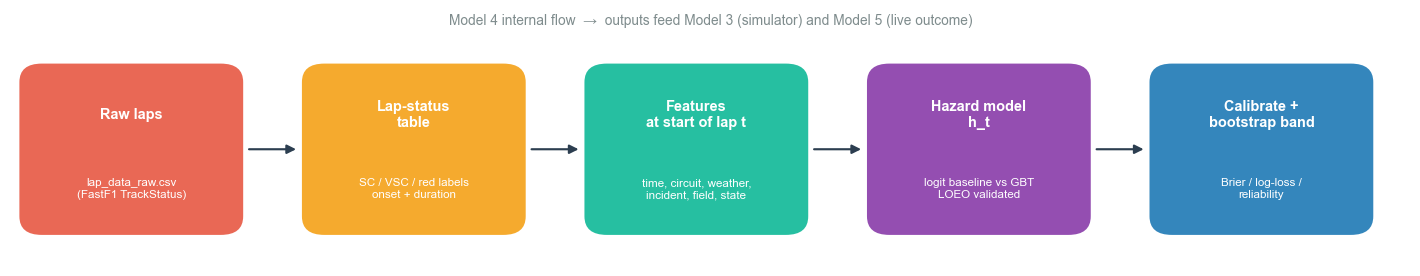

In [5]:
# ==============================================================================
# Architecture figure: where Model 4 sits
# ==============================================================================
def draw_pipeline(ax):
    ax.set_xlim(0, 100); ax.set_ylim(8, 30); ax.axis('off')
    steps = [
        ("Raw laps", "lap_data_raw.csv\n(FastF1 TrackStatus)", PAL['coral']),
        ("Lap-status\ntable", "SC / VSC / red labels\nonset + duration", PAL['amber']),
        ("Features\nat start of lap t", "time, circuit, weather,\nincident, field, state", PAL['teal']),
        ("Hazard model\nh_t", "logit baseline vs GBT\nLOEO validated", PAL['purple']),
        ("Calibrate +\nbootstrap band", "Brier / log-loss /\nreliability", PAL['blue']),
    ]
    w, gap = 15.2, 5.0
    for i, (title, sub, col) in enumerate(steps):
        x = 1 + i * (w + gap)
        ax.add_patch(FancyBboxPatch((x, 11), w, 14, boxstyle='round,pad=0.4,rounding_size=1.6',
                                    fc=col, ec='none', alpha=0.95))
        ax.text(x + w / 2, 21.0, title, ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
        ax.text(x + w / 2, 14.6, sub, ha='center', va='center', color='white', fontsize=7.6)
        if i < len(steps) - 1:
            ax.add_patch(FancyArrowPatch((x + w + 0.6, 18), (x + w + gap - 0.6, 18),
                                         arrowstyle='-|>', mutation_scale=12, color=PAL['ink'], lw=1.4))
    ax.text(50, 28.8, "Model 4 internal flow  →  outputs feed Model 3 (simulator) and Model 5 (live outcome)",
            ha='center', fontsize=9, color=PAL['grey'])

fig, ax = plt.subplots(figsize=(13, 2.6))
draw_pipeline(ax)
plt.tight_layout(); plt.show()

## 3. Data Acquisition (shared with Model 1)

Model 4 reads the **same canonical file** as Model 1: `lap_data_raw.csv`, one row per *driver-lap*, with FastF1 columns (`EventName`, `CircuitName`, `Driver`, `LapNumber`, `TrackStatus`, `Compound`, `TyreLife`, `LapTimeSeconds`, `PitInTime`, `PitOutTime`, `Time`, `TrackTemp`, `AirTemp`, `Humidity`, `Rainfall`, `TotalLaps`, …).

In [6]:
# ==============================================================================
# 3. Data Ingestion: canonical raw dataset (+ schema-compatible synthetic fallback)
# ==============================================================================
RAW_DATA_PATH = PROJECT_ROOT / 'lap_data_raw.csv'
USE_SYNTHETIC_IF_MISSING = False    

def make_synthetic_raw(seed: int = 11) -> pd.DataFrame:
    """Schema-compatible stand-in for lap_data_raw.csv (for pipeline testing ONLY)."""
    rng = np.random.default_rng(seed)
    cal = [('Australia', 58, 81, 1), ('China', 56, 96, 0), ('Japan', 53, 92, 0), ('Miami', 57, 90, 1),
           ('Canada', 70, 76, 1), ('Monaco', 78, 74, 2), ('Barcelona', 66, 79, 0), ('Austria', 71, 67, 0),
           ('Great Britain', 52, 89, 0), ('Belgium', 44, 106, 0), ('Hungary', 70, 79, 0),
           ('Netherlands', 72, 72, 0), ('Italy', 53, 82, 0), ('Spain', 57, 83, 1), ('Azerbaijan', 51, 104, 2),
           ('Bahrain', 57, 95, 0), ('Singapore', 62, 100, 2)]
    drivers = ['VER', 'NOR', 'LEC', 'HAM', 'RUS', 'PIA', 'ALO', 'SAI', 'GAS', 'ALB',
               'STR', 'TSU', 'OCO', 'HUL', 'BEA', 'LAW', 'ANT', 'COL', 'BOR', 'HAD']
    team_of = {d: f"Team{i // 2}" for i, d in enumerate(drivers)}
    frames = []
    for gp, T, base, street in cal:
        rainy, openf1_like = (gp == 'Belgium'), (gp == 'Bahrain')
        status = np.zeros(T + 3, int)                      # 0 green, 1 SC, 2 VSC
        lap = 1
        while lap <= T:
            h = 0.010 * (1 + 0.9 * street) * (7 if lap == 1 else 1)
            h *= (2.4 if (rainy and 15 <= lap <= 34) else 1) * (0.5 if lap > T - 3 else 1)
            if rng.random() < h:
                typ = 1 if rng.random() < 0.65 else 2
                dur = int(rng.integers(3, 7)) if typ == 1 else int(rng.integers(2, 4))
                for k in range(dur):
                    if lap + k <= T:
                        status[lap + k] = typ
                lap += dur + 1
            else:
                lap += 1
        yellow = rng.random(T + 3) < 0.04
        for l in range(2, T + 1):
            if status[l] > 0 and status[l - 1] == 0 and rng.random() < 0.6:
                yellow[l - 1] = True
        st_str = []
        for l in range(T + 1):
            if l == 0: st_str.append('1'); continue
            s, first, last = status[l], status[l - 1] == 0, status[l + 1] == 0
            if s == 1:   st_str.append(('1' if first else '') + '4' + ('1' if last else ''))
            elif s == 2: st_str.append(('1' if first else '') + '6' + ('7' if last else ''))
            else:        st_str.append('12' if yellow[l] else '1')
        temp0 = rng.uniform(24, 46)
        for gi, d in enumerate(drivers):
            retire = rng.integers(8, T) if rng.random() < 0.12 else T + 1
            n_stops = int(rng.integers(1, 3))
            planned = sorted(rng.integers(12, T - 8, size=n_stops).tolist())
            stint, tyre_age, pits_done = 1, 0, 0
            cmp_seq = list(rng.permutation(['SOFT', 'MEDIUM', 'HARD']))
            t_cum = 0.35 * gi
            for l in range(1, T + 1):
                if l > retire: break
                tyre_age += 1
                cmpd = cmp_seq[(stint - 1) % 3]
                pit_in = (pits_done < len(planned) and l == planned[pits_done]) or \
                         (status[l] > 0 and pits_done < 2 and tyre_age > 8 and rng.random() < 0.35)
                deg = {'SOFT': 0.07, 'MEDIUM': 0.045, 'HARD': 0.03}[cmpd] * tyre_age
                lt = base + (T - l) * 1.75 * 0.035 + deg + 0.15 * (gi // 2) + rng.normal(0, 0.35)
                if l == 1: lt += 6
                if status[l] == 1: lt *= 1.45 + rng.normal(0, 0.03)
                elif status[l] == 2: lt *= 1.32 + rng.normal(0, 0.03)
                elif yellow[l] and rng.random() < 0.3: lt += 0.8
                pit_out = bool(stint > 1 and tyre_age == 1)
                if pit_in: lt += 3.0
                if pit_out: lt += 20.0 if status[l] == 0 else 11.0
                t_cum += lt
                wet = rainy and 16 <= l <= 34
                frames.append((f"2026_{gp}", gp, 2026, T, d, gi + 1, team_of[d], float(l), float(stint),
                               'INTERMEDIATE' if wet else cmpd, float(tyre_age), lt, t_cum,
                               1.0 if pit_in else np.nan, 1.0 if pit_out else np.nan,
                               '1' if openf1_like else st_str[l],
                               temp0 + 0.04 * l + rng.normal(0, 0.3), temp0 - 10 + rng.normal(0, 0.2),
                               50 + rng.normal(0, 1.0) + (25 if rainy else 0), bool(wet), True))
                if pit_in:
                    stint += 1; tyre_age = 0; pits_done += 1
    cols = ['EventName', 'CircuitName', 'Year', 'TotalLaps', 'Driver', 'DriverNumber', 'Team', 'LapNumber', 'Stint',
            'Compound', 'TyreLife', 'LapTimeSeconds', 'Time', 'PitInTime', 'PitOutTime', 'TrackStatus',
            'TrackTemp', 'AirTemp', 'Humidity', 'Rainfall', 'IsAccurate']
    out = pd.DataFrame(frames, columns=cols)
    out['PitInTime'] = pd.to_timedelta(out['PitInTime'], unit='s')
    out['PitOutTime'] = pd.to_timedelta(out['PitOutTime'], unit='s')
    out['LapTime'] = pd.to_timedelta(out['LapTimeSeconds'], unit='s')
    out['Time'] = pd.to_timedelta(out['Time'], unit='s')
    return out

SYNTHETIC = False
if RAW_DATA_PATH.exists():
    print(f"Loading pre-assembled raw dataset from {RAW_DATA_PATH} ...")
    raw_df = pd.read_csv(RAW_DATA_PATH, low_memory=False)
elif USE_SYNTHETIC_IF_MISSING:
    SYNTHETIC = True
    raw_df = make_synthetic_raw()
    print("=" * 78)
    print("  !!  lap_data_raw.csv NOT FOUND  ->  SYNTHETIC DEMO DATA IN USE  !!")
    print("  Every number and figure below is a pipeline test, NOT an F1 result.")
    print("=" * 78)
else:
    raise FileNotFoundError(f"{RAW_DATA_PATH} not found. Run the Model 1 data cell first, or enable the synthetic fallback.")

TAG = '  [SYNTHETIC DATA]' if SYNTHETIC else ''
print(f"Raw dataset: {len(raw_df):,} driver-laps | {raw_df['EventName'].nunique()} events | {raw_df.shape[1]} columns")
raw_df[['EventName', 'Driver', 'LapNumber', 'Compound', 'TyreLife', 'TrackStatus']].head()

Loading pre-assembled raw dataset from /Users/hemant/Work/StintIQ/Model Development/lap_data_raw.csv ...
Raw dataset: 19,644 driver-laps | 17 events | 59 columns


,EventName,Driver,LapNumber,Compound,TyreLife,TrackStatus
0,2026_Australia,NOR,1.0,MEDIUM,1.0,1
1,2026_Australia,NOR,2.0,MEDIUM,2.0,1
2,2026_Australia,NOR,3.0,MEDIUM,3.0,1
3,2026_Australia,NOR,4.0,MEDIUM,4.0,1
4,2026_Australia,NOR,5.0,MEDIUM,5.0,1


In [7]:
# ==============================================================================
# 3.1 Schema check + normalisation (tolerant of FastF1 / OpenF1 quirks)
# ==============================================================================
REQUIRED = ['EventName', 'Driver', 'LapNumber', 'TrackStatus']
OPTIONAL = ['CircuitName', 'TotalLaps', 'LapTimeSeconds', 'LapTime', 'Time', 'PitInTime', 'PitOutTime',
            'Compound', 'TyreLife', 'TrackTemp', 'AirTemp', 'Humidity', 'Rainfall']
missing_req = [c for c in REQUIRED if c not in raw_df.columns]
if missing_req:
    raise KeyError(f"Missing required columns: {missing_req}")
print("Optional columns missing (safe defaults will be used):", [c for c in OPTIONAL if c not in raw_df.columns] or 'none')

def to_seconds(s: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return pd.to_timedelta(s, errors='coerce').dt.total_seconds()

def prepare_raw(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy()
    df['LapNumber'] = pd.to_numeric(df['LapNumber'], errors='coerce')
    df = df.dropna(subset=['EventName', 'Driver', 'LapNumber']).copy()
    df['LapNumber'] = df['LapNumber'].astype(int)

    # FastF1 TrackStatus is a string of codes met during the lap: 1 clear, 2 yellow, 4 SC, 5 red, 6 VSC, 7 VSC ending.
    # CSV round-trips can turn '12' into 12 or 1.0 -> normalise to clean strings.
    ts = df['TrackStatus'].fillna('').astype(str).str.replace(r'\.0$', '', regex=True)
    df['_ts'] = ts
    df['f_yellow'] = ts.str.contains('2')
    df['f_sc'] = ts.str.contains('4')
    df['f_red'] = ts.str.contains('5')
    df['f_vsc'] = ts.str.contains('6') | ts.str.contains('7')

    if 'LapTimeSeconds' not in df.columns or df['LapTimeSeconds'].isna().all():
        df['LapTimeSeconds'] = to_seconds(df['LapTime']) if 'LapTime' in df.columns else np.nan
    df['LapTimeSeconds'] = pd.to_numeric(df['LapTimeSeconds'], errors='coerce')
    df['Time_s'] = to_seconds(df['Time']) if 'Time' in df.columns else np.nan

    pit_in = df['PitInTime'].notna() if 'PitInTime' in df.columns else pd.Series(False, index=df.index)
    pit_out = df['PitOutTime'].notna() if 'PitOutTime' in df.columns else pd.Series(False, index=df.index)
    df['is_pit'] = (pit_in | pit_out).astype(bool)
    df['is_pit_in'] = pit_in.astype(bool)

    df['Compound'] = df['Compound'].astype(str).str.upper() if 'Compound' in df.columns else 'UNKNOWN'
    df['is_wet_tyre'] = df['Compound'].isin(['INTERMEDIATE', 'WET']).astype(float)
    df['TyreLife'] = pd.to_numeric(df['TyreLife'], errors='coerce') if 'TyreLife' in df.columns else np.nan
    for c, d in [('TrackTemp', 35.0), ('AirTemp', 25.0), ('Humidity', 50.0)]:
        df[c] = pd.to_numeric(df[c], errors='coerce').fillna(d) if c in df.columns else d
    df['Rainfall'] = (df['Rainfall'].map(lambda v: str(v).strip().lower() in ('true', '1', '1.0')).astype(float)
                      if 'Rainfall' in df.columns else 0.0)
    if 'CircuitName' not in df.columns:
        df['CircuitName'] = df['EventName'].astype(str).str.replace(r'^\d{4}_', '', regex=True)
    if 'TotalLaps' not in df.columns or df['TotalLaps'].isna().all():
        df['TotalLaps'] = df.groupby('EventName')['LapNumber'].transform('max')
    df['TotalLaps'] = pd.to_numeric(df['TotalLaps'], errors='coerce')
    df['TotalLaps'] = df['TotalLaps'].fillna(df.groupby('EventName')['LapNumber'].transform('max'))
    return df.sort_values(['EventName', 'Driver', 'LapNumber']).reset_index(drop=True)

df_raw = prepare_raw(raw_df)
print(f"Prepared: {len(df_raw):,} driver-laps | status codes seen: {sorted(set(''.join(df_raw['_ts'].unique())))}")

Optional columns missing (safe defaults will be used): none
Prepared: 19,644 driver-laps | status codes seen: ['1', '2', '6', '7']


## 4. Lap-Status Table: Labels and Features

This is the heart of Model 4. Raw driver-laps are collapsed to **one row per race-lap**, and every feature is built from laps **≤ t−1** so that the row for lap $t$ only contains what a strategist would know at the start of that lap.

| Feature group | Features (at start of lap $t$) | Rationale |
|---|---|---|
| **time** | `progress`, `laps_remaining`, `is_lap1` | opening-lap and late-race hazard differ |
| **circuit** | `street_level`, `wall_risk`, (`hist_sc_rate`) | barriers close to the track, run-off, history |
| **weather** | `rain_prev`, `wet_frac_prev`, temps, humidity, `rain_change` | wet/transition laps raise incident risk |
| **incident** | `yellow_prev`, `yellow_max3`, `slow_frac_prev`, `pace_spread_prev`, `retired_prev` | the "current incident signal" from the technical document |
| **field** | `pit_frac_prev`, `tyre_mean_prev`, `compression_prev` | traffic density, pit activity, old tyres |
| **state** | `laps_since_neut`, `n_prior_neut`, `restart_window` | bunching and re-start risk after a previous neutralisation |

`slow_frac_prev` is a model-free proxy for "cars lapping far slower than their own recent pace". If Model 1's out-of-fold residuals are exported (Section 10), the same idea can use Model 1's expected pace instead.

In [8]:
# ==============================================================================
# 4.1 Configuration: label thresholds + circuit metadata
# ==============================================================================
STATUS_MIN_FRAC = 0.15        # share of cars whose lap carries the flag for the lap to count as flagged
SLOW_RATIO = 1.07             # lap > 7 % slower than the driver's own recent clean pace -> "slow car"
PACE_NEUTRAL_RATIO = 1.20     # field-median lap >= 1.20x recent pace -> neutralisation-like (QC only)
RESCUE_SUSPECT_EVENTS = False # if True, events with no usable TrackStatus get pace-inferred labels

# Analyst-editable circuit priors (NOT learned from data; edit freely).
# street_level: 0 permanent, 1 semi-street / temporary, 2 full street circuit
# wall_risk   : 1 generous run-off ... 3 barriers right at the track edge
CIRCUIT_META = {
    'Australia': (1, 2), 'China': (0, 1), 'Japan': (0, 2), 'Miami': (1, 2), 'Canada': (1, 3),
    'Monaco': (2, 3), 'Barcelona': (0, 1), 'Austria': (0, 1), 'Great Britain': (0, 1), 'Belgium': (0, 2),
    'Hungary': (0, 1), 'Netherlands': (0, 2), 'Italy': (0, 1), 'Spain': (1, 2), 'Azerbaijan': (2, 3),
    'Bahrain': (0, 1), 'Singapore': (2, 3),
}
unknown = sorted(set(df_raw['CircuitName'].unique()) - set(CIRCUIT_META))
if unknown:
    print(f"[WARN] No circuit metadata for {unknown} -> default (0, 2). Add them to CIRCUIT_META.")

# Optional external prior: historical SC/VSC rate per circuit from PRIOR seasons (never the target season).
HISTORY_PATH = PROJECT_ROOT / 'circuit_sc_history.csv'
RUN_HISTORY_BUILD = False     # needs network + FastF1 cache; leave False unless you want to (re)build it
HISTORY_YEARS = [2023, 2024, 2025]

def build_circuit_history(gp_names, years, out_path):
    """Per-circuit SC/VSC onsets per lap from past seasons via FastF1 track_status (shrunk to the global mean)."""
    import fastf1
    rows = []
    for gp in gp_names:
        n_ev = n_laps = 0
        for yr in years:
            try:
                s = fastf1.get_session(yr, gp, 'R')
                s.load(laps=True, telemetry=False, weather=False, messages=False)
                st = s.track_status['Status'].astype(str).tolist()
                neutral = [x in ('4', '6', '7') for x in st]
                n_ev += sum(1 for a, b in zip([False] + neutral[:-1], neutral) if b and not a)
                n_laps += int(s.total_laps)
            except Exception as exc:
                print(f"  [skip] {yr} {gp}: {type(exc).__name__}")
        rows.append((gp, n_ev, n_laps))
    h = pd.DataFrame(rows, columns=['CircuitName', 'n_events', 'n_laps'])
    g_rate = h['n_events'].sum() / max(h['n_laps'].sum(), 1)
    k = 150.0                                           # prior strength in laps
    h['hist_sc_rate'] = (h['n_events'] + g_rate * k) / (h['n_laps'] + k)
    h.to_csv(out_path, index=False)
    return h

if RUN_HISTORY_BUILD:
    build_circuit_history(sorted(df_raw['CircuitName'].unique()), HISTORY_YEARS, HISTORY_PATH)
HISTORY = pd.read_csv(HISTORY_PATH)[['CircuitName', 'hist_sc_rate']] if HISTORY_PATH.exists() else None
print("Circuit history prior:", "loaded" if HISTORY is not None else "not available (feature skipped)")

Circuit history prior: not available (feature skipped)


In [9]:
# ==============================================================================
# 4.2 Per-driver pace ratio (past-only reference) -> slow-car / pace-anomaly signals
# ==============================================================================
def add_driver_pace_ratio(d_in: pd.DataFrame) -> pd.DataFrame:
    d = d_in.sort_values(['EventName', 'Driver', 'LapNumber']).reset_index(drop=True).copy()
    neutral_car = d['f_sc'] | d['f_vsc'] | d['f_red']
    clean = d['LapTimeSeconds'].where(~d['is_pit'] & ~neutral_car)      # clean green-ish laps only
    keys = [d['EventName'], d['Driver']]
    # reference = median of the driver's previous clean laps (shift(1) => strictly past information)
    ref = clean.groupby(keys).transform(lambda s: s.shift(1).rolling(6, min_periods=2).median())
    ref = ref.groupby(keys).ffill()
    d['pace_ratio'] = d['LapTimeSeconds'] / ref
    d['elig'] = (~d['is_pit']) & d['pace_ratio'].notna()
    d['ratio_elig'] = d['pace_ratio'].where(d['elig'])
    d['slow'] = (d['elig'] & (d['pace_ratio'] > SLOW_RATIO) & ~neutral_car).astype(float)
    return d

def build_lap_table(d: pd.DataFrame, horizon: dict = None) -> pd.DataFrame:
    """Collapse driver-laps to race-laps. Features for lap t use laps <= t-1 only.
    `horizon` ({event: last_lap}) lets the leakage test extend a truncated race by one empty lap."""
    keys = ['EventName', 'LapNumber']
    g = d.groupby(keys)
    agg = g.agg(CircuitName=('CircuitName', 'first'), TotalLaps=('TotalLaps', 'max'), n_cars=('Driver', 'nunique'),
                frac_sc=('f_sc', 'mean'), frac_vsc=('f_vsc', 'mean'), frac_red=('f_red', 'mean'),
                frac_yellow=('f_yellow', 'mean'), pit_frac=('is_pit', 'mean'), tyre_mean=('TyreLife', 'mean'),
                w_rain=('Rainfall', 'mean'), w_wet=('is_wet_tyre', 'mean'), w_track=('TrackTemp', 'mean'),
                w_air=('AirTemp', 'mean'), w_hum=('Humidity', 'mean'), slow_n=('slow', 'sum'),
                elig_n=('elig', 'sum'), ratio_med=('ratio_elig', 'median'), pit_in_n=('is_pit_in', 'sum'))
    agg['ratio_iqr'] = g['ratio_elig'].quantile(0.75) - g['ratio_elig'].quantile(0.25)

    # field compression: share of consecutive finishers within 2 s (same proxy basis as Model 1's TimeGapAhead)
    tt = d.dropna(subset=['Time_s']).sort_values(['EventName', 'LapNumber', 'Time_s'])
    gap = tt.groupby(keys)['Time_s'].diff()
    tt = tt.assign(close=(gap < 2.0).astype(float).where(gap.notna()))
    agg['compression'] = tt.groupby(keys)['close'].mean()
    agg = agg.reset_index()

    codes = d.groupby('EventName')['_ts'].agg(lambda s: set(''.join(s.unique())))
    suspect_events = {ev for ev, c in codes.items() if c <= {'1'}}          # only '1' ever seen -> flags not logged

    out = []
    for ev, e in agg.groupby('EventName'):
        e = e.set_index('LapNumber').sort_index()
        total = int(e['TotalLaps'].max())
        last = int(horizon.get(ev, e.index.max())) if horizon else int(e.index.max())
        e = e.reindex(pd.RangeIndex(1, last + 1, name='LapNumber'))
        e['EventName'] = ev
        e['CircuitName'] = e['CircuitName'].ffill().bfill()
        e['TotalLaps'] = total
        e['has_data'] = e['n_cars'].notna()

        sc = (e['frac_sc'] >= STATUS_MIN_FRAC).astype(bool)
        vsc = ((e['frac_vsc'] >= STATUS_MIN_FRAC) & ~sc).astype(bool)
        red = (e['frac_red'] >= STATUS_MIN_FRAC).astype(bool)
        suspect = ev in suspect_events
        if suspect and RESCUE_SUSPECT_EVENTS:                                  # label-side look-ahead, QC use only
            hi = (e['ratio_med'] >= PACE_NEUTRAL_RATIO)
            sc = sc | (hi & (hi.shift(1, fill_value=False) | hi.shift(-1, fill_value=False)))
        neutral = sc | vsc
        neutral_all = (neutral | red)
        prev_neutral = neutral_all.shift(1, fill_value=False).astype(bool)
        onset = neutral & ~prev_neutral
        e['status'] = np.where(red, 'RED', np.where(sc, 'SC', np.where(vsc, 'VSC', 'GREEN')))
        e['obs_yellow'] = (e['frac_yellow'] >= STATUS_MIN_FRAC).astype(bool)
        e['neutral'] = neutral
        e['neutral_all'] = neutral_all
        e['onset'] = onset
        e['y_any'] = onset.astype(int)
        e['y_sc'] = (onset & sc).astype(int)
        e['y_vsc'] = (onset & ~sc & vsc).astype(int)
        e['onset_type'] = np.where(onset, np.where(sc, 'SC', 'VSC'), '')
        e['at_risk'] = (~prev_neutral) & (~red)
        e['suspect_status'] = suspect
        e['label_reliable'] = (not suspect) or RESCUE_SUSPECT_EVENTS

        # --- state features (laps <= t-1) -----------------------------------------------------
        nv, ov = neutral_all.values, onset.values
        since, nprior, last_neut, cnt = [], [], 0, 0
        for t in e.index.values:
            since.append(min((t - 1) - last_neut, 40)); nprior.append(cnt)
            if nv[t - 1]: last_neut = t
            if ov[t - 1]: cnt += 1
        e['laps_since_neut'] = since
        e['n_prior_neut'] = nprior
        e['restart_window'] = ((e['n_prior_neut'] > 0) & (e['laps_since_neut'] <= 2)).astype(float)

        # --- previous-lap observables ------------------------------------------------------------
        lag = lambda col, fill: e[col].shift(1).fillna(fill)
        e['yellow_prev'] = lag('frac_yellow', 0.0)
        e['yellow_max3'] = e['frac_yellow'].shift(1).rolling(3, min_periods=1).max().fillna(0.0)
        e['slow_frac_prev'] = (e['slow_n'] / e['elig_n'].replace(0, np.nan)).shift(1).fillna(0.0)
        e['pace_spread_prev'] = lag('ratio_iqr', 0.0)
        n_start = e['n_cars'].iloc[:3].max()
        e['retired_prev'] = (n_start - e['n_cars'].shift(1)).clip(lower=0).fillna(0.0)
        e['pit_frac_prev'] = lag('pit_frac', 0.0)
        e['tyre_mean_prev'] = lag('tyre_mean', 0.0)
        e['compression_prev'] = e['compression'].shift(1)                      # NaN on lap 1 -> imputed
        for src, dst in [('w_rain', 'rain_prev'), ('w_wet', 'wet_frac_prev'), ('w_track', 'track_temp'),
                         ('w_air', 'air_temp'), ('w_hum', 'humidity')]:
            s = e[src].shift(1)
            s.iloc[0] = e[src].iloc[0]                                         # pre-race reading for lap 1
            e[dst] = s
        e['rain_change'] = (e['rain_prev'] - e['rain_prev'].shift(1)).fillna(0.0)

        # --- time features -----------------------------------------------------------------------
        e['progress'] = e.index.values / total
        e['laps_remaining'] = total - e.index.values
        e['is_lap1'] = (e.index.values == 1).astype(float)
        out.append(e.reset_index())

    lap = pd.concat(out, ignore_index=True)
    meta = lap['CircuitName'].map(lambda c: CIRCUIT_META.get(c, (0, 2)))
    lap['street_level'] = [m[0] for m in meta]
    lap['wall_risk'] = [m[1] for m in meta]
    if HISTORY is not None:
        lap = lap.merge(HISTORY, on='CircuitName', how='left')
    return lap

d_paced = add_driver_pace_ratio(df_raw)
LAP = build_lap_table(d_paced)
print(f"Lap table: {len(LAP):,} race-laps | {LAP['EventName'].nunique()} events | "
      f"{int(LAP.loc[LAP.has_data, 'onset'].sum())} neutralisation onsets "
      f"(SC {int(LAP['y_sc'].sum())}, VSC {int(LAP['y_vsc'].sum())})")
LAP.loc[LAP.has_data, ['EventName', 'LapNumber', 'status', 'onset', 'yellow_prev', 'slow_frac_prev',
                       'laps_since_neut', 'progress']].head()

Lap table: 1,024 race-laps | 17 events | 6 neutralisation onsets (SC 0, VSC 6)


,EventName,LapNumber,status,onset,yellow_prev,slow_frac_prev,laps_since_neut,progress
0,2026_Australia,1,GREEN,False,0.0,0.0,0,0.017241
1,2026_Australia,2,GREEN,False,0.0,0.0,1,0.034483
2,2026_Australia,3,GREEN,False,0.0,0.0,2,0.051724
3,2026_Australia,4,GREEN,False,0.0,0.0,3,0.068966
4,2026_Australia,5,GREEN,False,0.0,0.0,4,0.086207


In [10]:
# ==============================================================================
# 4.3 Feature groups (fixed once, used by the leakage test, the models and the ablations)
# ==============================================================================
FEATURE_GROUPS = {
    'time':     ['progress', 'laps_remaining', 'is_lap1'],
    'circuit':  ['street_level', 'wall_risk'] + (['hist_sc_rate'] if 'hist_sc_rate' in LAP.columns else []),
    'weather':  ['rain_prev', 'wet_frac_prev', 'track_temp', 'air_temp', 'humidity', 'rain_change'],
    'incident': ['yellow_prev', 'yellow_max3', 'slow_frac_prev', 'pace_spread_prev', 'retired_prev'],
    'field':    ['pit_frac_prev', 'tyre_mean_prev', 'compression_prev'],
    'state':    ['laps_since_neut', 'n_prior_neut', 'restart_window'],
}
ALL_FEATURES = [c for grp in FEATURE_GROUPS.values() for c in grp]
for k, v in FEATURE_GROUPS.items():
    print(f"{k:<9} ({len(v)}): {v}")

time      (3): ['progress', 'laps_remaining', 'is_lap1']
circuit   (2): ['street_level', 'wall_risk']
weather   (6): ['rain_prev', 'wet_frac_prev', 'track_temp', 'air_temp', 'humidity', 'rain_change']
incident  (5): ['yellow_prev', 'yellow_max3', 'slow_frac_prev', 'pace_spread_prev', 'retired_prev']
field     (3): ['pit_frac_prev', 'tyre_mean_prev', 'compression_prev']
state     (3): ['laps_since_neut', 'n_prior_neut', 'restart_window']


### 4.4 Information-boundary test (leakage guard)
The technical document requires reconstructing the information boundary at every lap. The test below **deletes every row from lap $t$ onward**, rebuilds the table from the truncated race, and checks that the feature vector for lap $t$ is *identical* to the one from the full race. Any mismatch means a feature peeked at the future.

In [11]:
# ==============================================================================
# 4.4 Leakage test: features for lap t must be reproducible from laps <= t-1
# ==============================================================================
def leakage_test(df_prepared, lap_table, feature_cols, n_checks=15, seed=0):
    rng = np.random.default_rng(seed)
    ok_events = lap_table.loc[lap_table['label_reliable'] & lap_table['has_data'], 'EventName'].unique()
    bad = []
    for _ in range(n_checks):
        ev = rng.choice(ok_events)
        sub = lap_table[(lap_table['EventName'] == ev) & lap_table['has_data']]
        t0 = int(rng.integers(6, int(sub['LapNumber'].max())))
        cut = add_driver_pace_ratio(df_prepared[(df_prepared['EventName'] == ev) & (df_prepared['LapNumber'] <= t0 - 1)])
        tab = build_lap_table(cut, horizon={ev: t0})
        a = tab.loc[(tab['EventName'] == ev) & (tab['LapNumber'] == t0), feature_cols].iloc[0].astype(float).values
        b = sub.loc[sub['LapNumber'] == t0, feature_cols].iloc[0].astype(float).values
        diff = [c for c, x, y in zip(feature_cols, a, b) if not np.isclose(x, y, equal_nan=True, atol=1e-9)]
        if diff:
            bad.append((ev, t0, diff))
    return bad

leaks = leakage_test(df_raw, LAP, ALL_FEATURES)
if leaks:
    print("LEAKAGE DETECTED:"); [print("  ", x) for x in leaks[:10]]
    raise AssertionError("Feature construction uses future information.")
print(f"Information-boundary test passed: 15 random (event, lap) pairs reproduce all {len(ALL_FEATURES)} features from laps <= t-1.")

Information-boundary test passed: 15 random (event, lap) pairs reproduce all 22 features from laps <= t-1.


## 5. Label Quality Audit

Two checks before any modelling:
1. **Is `TrackStatus` actually logged?** Model 1's OpenF1 fallback writes `TrackStatus = '1'` for every lap. An event whose only code is `'1'` has **no usable SC/VSC labels** and would teach the model that neutralisations never happen. Such events are flagged `suspect` and excluded by default.
2. **Do flags agree with pace?** Laps whose field-median pace is ≥ 1.20× normal but labelled green (`hidden_slow_laps`) indicate unflagged slow periods.

In [12]:
# ==============================================================================
# 5. Per-event label audit
# ==============================================================================
codes_by_event = df_raw.groupby('EventName')['_ts'].agg(lambda s: ''.join(sorted(set(''.join(s.unique())))))
L = LAP[LAP['has_data']]
audit = (L.groupby('EventName')
           .agg(laps=('LapNumber', 'max'),
                sc_laps=('status', lambda s: int((s == 'SC').sum())),
                vsc_laps=('status', lambda s: int((s == 'VSC').sum())),
                red_laps=('status', lambda s: int((s == 'RED').sum())),
                onsets=('onset', 'sum'),
                suspect=('suspect_status', 'first')))
hidden = L[(L['status'] == 'GREEN') & (L['ratio_med'] >= PACE_NEUTRAL_RATIO)].groupby('EventName').size()
audit['hidden_slow_laps'] = hidden.reindex(audit.index).fillna(0).astype(int)
audit.insert(1, 'codes_seen', codes_by_event.reindex(audit.index))
audit['usable_for_training'] = (~audit['suspect']) | RESCUE_SUSPECT_EVENTS
audit['onsets'] = audit['onsets'].astype(int)
display_cols = ['laps', 'codes_seen', 'sc_laps', 'vsc_laps', 'red_laps', 'onsets', 'hidden_slow_laps', 'suspect', 'usable_for_training']
print(audit[display_cols].to_string())
n_bad = int(audit['suspect'].sum())
print(f"\n{n_bad} event(s) flagged as suspect (no usable TrackStatus). Excluded from training unless RESCUE_SUSPECT_EVENTS=True.")
if n_bad:
    print("Suspect events:", list(audit.index[audit['suspect']]))

                    laps codes_seen  sc_laps  vsc_laps  red_laps  onsets  hidden_slow_laps  suspect  usable_for_training
EventName                                                                                                               
2026_Australia        58       1267        0         9         0       3                 0    False                 True
2026_Austria          71          1        0         0         0       0                 1     True                False
2026_Azerbaijan       51          1        0         0         0       0                 4     True                False
2026_Bahrain          55          1        0         0         0       0                 6     True                False
2026_Barcelona        66       1267        0        10         0       2                 0    False                 True
2026_Belgium          45          1        0         0         0       0                 1     True                False
2026_Canada           68        

## 6. Exploratory Data Analysis

### 6.1 Race-status timeline
Every row is a race; every cell a lap. ▼ marks the lap a new neutralisation starts.

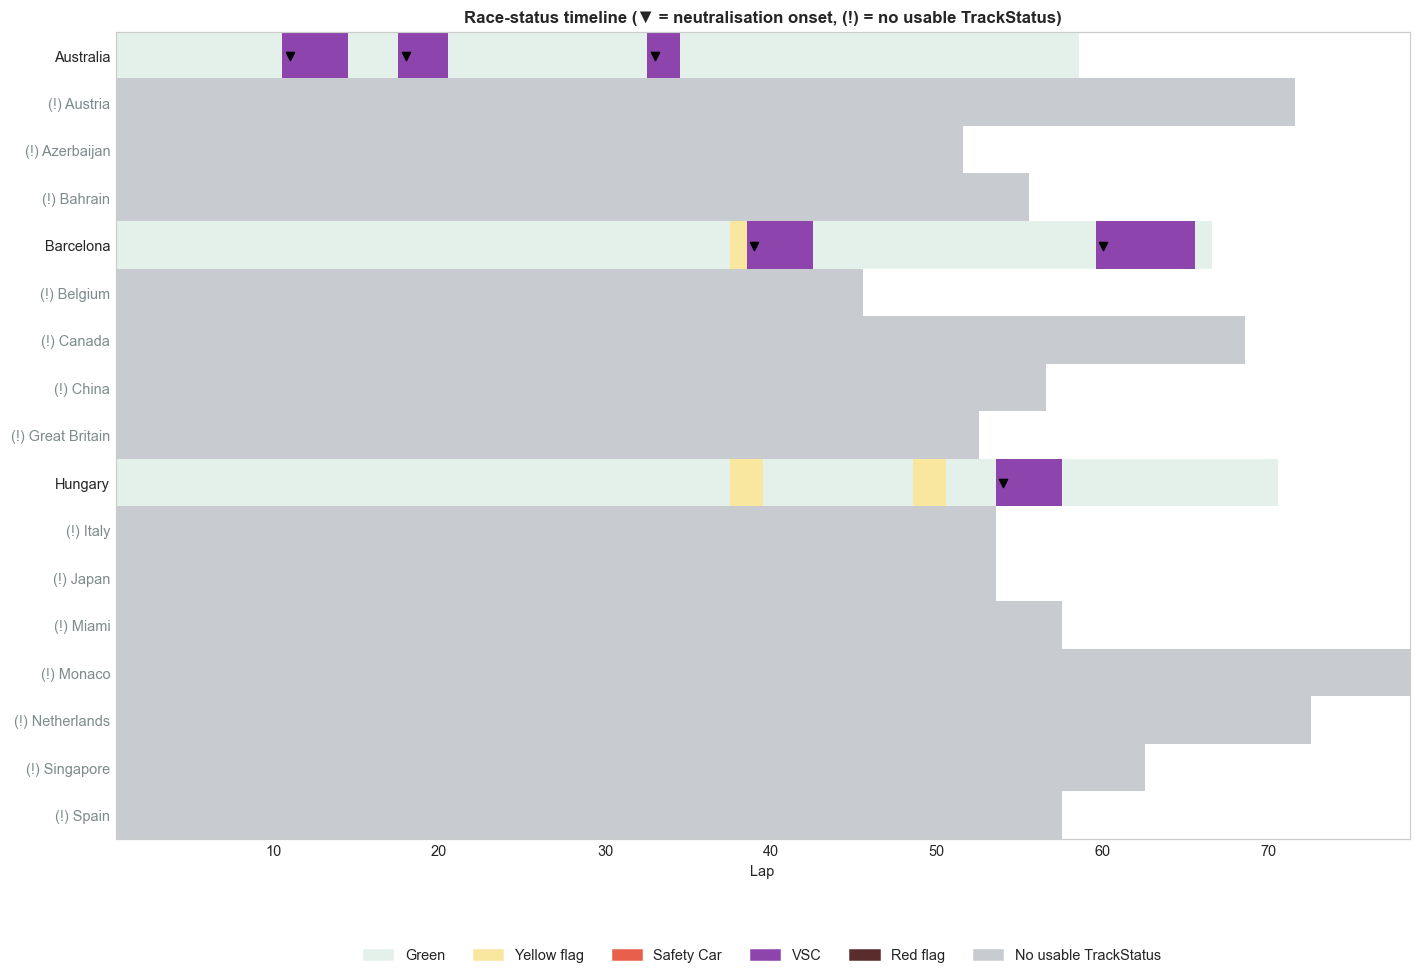

In [13]:
# ==============================================================================
# 6.1 Timeline heat-map of race status
# ==============================================================================
events = sorted(LAP['EventName'].unique())
max_lap = int(LAP['LapNumber'].max())
M = np.full((len(events), max_lap), np.nan)
for i, ev in enumerate(events):
    e = LAP[(LAP['EventName'] == ev) & LAP['has_data']]
    v = np.where(e['status'] == 'RED', 4, np.where(e['status'] == 'SC', 2,
        np.where(e['status'] == 'VSC', 3, np.where(e['obs_yellow'], 1, 0))))
    M[i, e['LapNumber'].values - 1] = v
    if e['suspect_status'].iloc[0]:
        M[i, e['LapNumber'].values - 1] = 5                      # grey: flags not logged for this event

cmap = ListedColormap(['#E3F1EA', '#F9E79F', PAL['coral'], PAL['purple'], '#5B2C2C', '#C8CCD0'])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)
fig, ax = plt.subplots(figsize=(13, 0.42 * len(events) + 1.8))
ax.imshow(np.ma.masked_invalid(M), aspect='auto', cmap=cmap, norm=norm, interpolation='nearest',
          extent=[0.5, max_lap + 0.5, len(events) - 0.5, -0.5])
for i, ev in enumerate(events):
    e = LAP[(LAP['EventName'] == ev) & LAP['onset']]
    ax.scatter(e['LapNumber'], np.full(len(e), i), marker='v', s=28, color='black', zorder=3)
sus = audit['suspect'].reindex(events).fillna(False).values
ax.set_yticks(range(len(events)))
ax.set_yticklabels([("(!) " if s else "") + ev.split('_', 1)[-1] for ev, s in zip(events, sus)])
for lab, s in zip(ax.get_yticklabels(), sus):
    if s: lab.set_color(PAL['grey'])
ax.set_xlabel('Lap'); ax.set_title('Race-status timeline (▼ = neutralisation onset, (!) = no usable TrackStatus)' + TAG)
ax.grid(False)
handles = [mpatches.Patch(color=c, label=l) for c, l in zip(['#E3F1EA', '#F9E79F', PAL['coral'], PAL['purple'], '#5B2C2C', '#C8CCD0'],
                                                             ['Green', 'Yellow flag', 'Safety Car', 'VSC', 'Red flag', 'No usable TrackStatus'])]
ax.legend(handles=handles, ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout(); plt.show()

### 6.2 Where in a race do neutralisations start?
Empirical hazard by race phase on the **at-risk laps of reliable events** (exact binomial 90 % intervals). This is the raw shape the spline baseline will try to learn — note how wide the intervals are. **Rare-event honesty:** with a few dozen events, most bins cannot distinguish between very different hazards.

Person-period table: 171 at-risk laps | 3 events | 6 onsets | base hazard = 0.0351 per lap


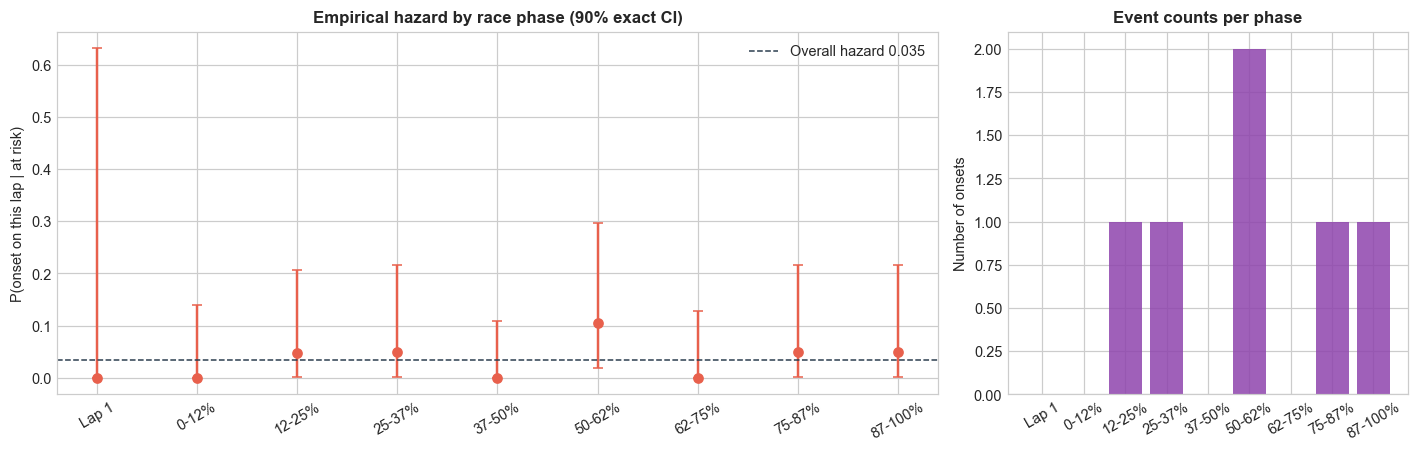

In [14]:
# ==============================================================================
# 6.2 Empirical hazard by race phase (+ exact binomial CIs)
# ==============================================================================
TRAIN = LAP[LAP['at_risk'] & LAP['has_data'] & LAP['label_reliable']].copy().reset_index(drop=True)
print(f"Person-period table: {len(TRAIN):,} at-risk laps | {TRAIN['EventName'].nunique()} events | "
      f"{int(TRAIN['y_any'].sum())} onsets | base hazard = {TRAIN['y_any'].mean():.4f} per lap")

def exact_ci(k, n, alpha=0.10):
    lo = stats.beta.ppf(alpha / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - alpha / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi

lap1 = TRAIN[TRAIN['LapNumber'] == 1]
rest = TRAIN[TRAIN['LapNumber'] > 1].copy()
rest['bin'] = pd.cut(rest['progress'], np.linspace(0, 1, 9), include_lowest=True)
rows = [('Lap 1', len(lap1), int(lap1['y_any'].sum()), 0.0)]
for b, gdf in rest.groupby('bin', observed=True):
    rows.append((f"{int(b.left*100)}-{int(b.right*100)}%", len(gdf), int(gdf['y_any'].sum()), gdf['progress'].mean()))
H = pd.DataFrame(rows, columns=['phase', 'n', 'k', 'prog'])
H['rate'] = H['k'] / H['n']
H[['lo', 'hi']] = [exact_ci(k, n) for k, n in zip(H['k'], H['n'])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
ax = axes[0]
x = np.arange(len(H))
ax.errorbar(x, H['rate'], yerr=[H['rate'] - H['lo'], H['hi'] - H['rate']], fmt='o', color=PAL['coral'], capsize=3, lw=1.6)
ax.axhline(TRAIN['y_any'].mean(), color=PAL['ink'], ls='--', lw=1, label=f"Overall hazard {TRAIN['y_any'].mean():.3f}")
ax.set_xticks(x); ax.set_xticklabels(H['phase'], rotation=30)
ax.set_ylabel('P(onset on this lap | at risk)'); ax.set_title('Empirical hazard by race phase (90% exact CI)' + TAG)
ax.legend(frameon=False)
ax = axes[1]
ax.bar(x, H['k'], color=PAL['purple'], alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(H['phase'], rotation=30)
ax.set_ylabel('Number of onsets'); ax.set_title('Event counts per phase')
plt.tight_layout(); plt.show()

### 6.3 Anatomy of a neutralisation: type, length, pace and pit behaviour
These four panels are not just descriptive — they define **what Model 3 needs from Model 4 besides timing**: how long a period lasts, how much slower the field is, and how strongly pit stops cluster under SC/VSC.

{'VSC': 6} | median duration (laps): {'VSC': 4.0}


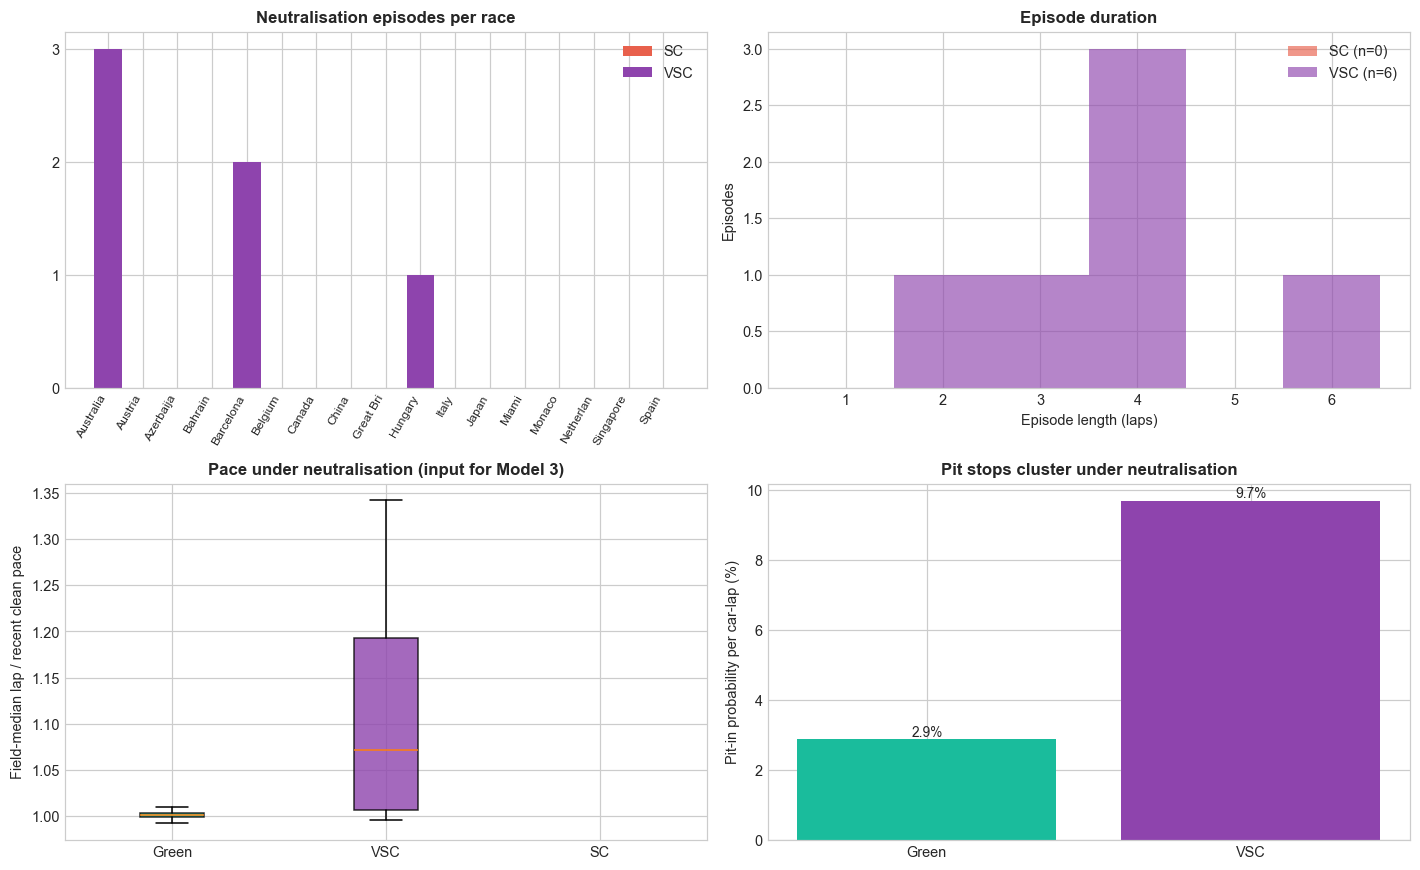

In [15]:
# ==============================================================================
# 6.3 Episodes, durations, pace under neutralisation, pit behaviour
# ==============================================================================
def extract_episodes(lap_table):
    rows = []
    for ev, e in lap_table[lap_table['has_data'] & lap_table['label_reliable']].groupby('EventName'):
        e = e.sort_values('LapNumber')
        ep = e['onset'].cumsum().where(e['neutral_all'], 0)
        for k in sorted(set(ep.unique()) - {0}):
            seg = e[ep == k]
            rows.append((ev, int(seg['LapNumber'].iloc[0]), len(seg), seg['onset_type'].iloc[0] or 'SC'))
    return pd.DataFrame(rows, columns=['EventName', 'start_lap', 'duration', 'type'])

EPISODES = extract_episodes(LAP)
print(EPISODES['type'].value_counts().to_dict(), "| median duration (laps):",
      EPISODES.groupby('type')['duration'].median().to_dict())

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
# (a) onsets per event, stacked by type
ax = axes[0, 0]
cnt = EPISODES.pivot_table(index='EventName', columns='type', values='start_lap', aggfunc='count').reindex(events).fillna(0)
for col in ['SC', 'VSC']:
    if col not in cnt.columns: cnt[col] = 0
ax.bar(range(len(cnt)), cnt['SC'], color=PAL['coral'], label='SC')
ax.bar(range(len(cnt)), cnt['VSC'], bottom=cnt['SC'], color=PAL['purple'], label='VSC')
ax.set_xticks(range(len(cnt))); ax.set_xticklabels([e.split('_', 1)[-1][:9] for e in cnt.index], rotation=60, ha='right', fontsize=8)
ax.set_title('Neutralisation episodes per race' + TAG); ax.legend(frameon=False)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
# (b) duration histograms
ax = axes[0, 1]
mx = max(int(EPISODES['duration'].max()) if len(EPISODES) else 6, 6)
for t, c in [('SC', PAL['coral']), ('VSC', PAL['purple'])]:
    v = EPISODES.loc[EPISODES['type'] == t, 'duration']
    ax.hist(v, bins=np.arange(0.5, mx + 1.5, 1), alpha=0.65, color=c, label=f"{t} (n={len(v)})")
ax.set_xlabel('Episode length (laps)'); ax.set_ylabel('Episodes'); ax.set_title('Episode duration'); ax.legend(frameon=False)
# (c) field pace under each status
ax = axes[1, 0]
Lh = LAP[LAP['has_data'] & LAP['label_reliable'] & LAP['ratio_med'].notna()]
groups = [Lh.loc[Lh['status'] == s, 'ratio_med'].clip(upper=2.5).values for s in ['GREEN', 'VSC', 'SC']]
bp = ax.boxplot([g if len(g) else [np.nan] for g in groups], patch_artist=True, showfliers=False)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['Green', 'VSC', 'SC'])
for patch, c in zip(bp['boxes'], [PAL['teal'], PAL['purple'], PAL['coral']]):
    patch.set_facecolor(c); patch.set_alpha(0.8)
ax.set_ylabel('Field-median lap / recent clean pace'); ax.set_title('Pace under neutralisation (input for Model 3)')
# (d) pit-in rate per car-lap by status
ax = axes[1, 1]
tmp = d_paced.merge(LAP[['EventName', 'LapNumber', 'status', 'label_reliable']], on=['EventName', 'LapNumber'], how='left')
tmp = tmp[tmp['label_reliable'].fillna(False).astype(bool)]
pit_rate = tmp.groupby('status')['is_pit_in'].mean().reindex(['GREEN', 'VSC', 'SC']) * 100
ax.bar(['Green', 'VSC', 'SC'], pit_rate.values, color=[PAL['teal'], PAL['purple'], PAL['coral']])
for i, v in enumerate(pit_rate.values):
    if np.isfinite(v): ax.text(i, v, f"{v:.1f}%", ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Pit-in probability per car-lap (%)'); ax.set_title('Pit stops cluster under neutralisation')
plt.tight_layout(); plt.show()

### 6.4 Do the engineered signals carry information?
Observed hazard split by tercile/flag of each key feature (90 % exact CI). A useful predictor shows a clear gradient — and non-overlapping intervals are the exception, not the rule, at this sample size.

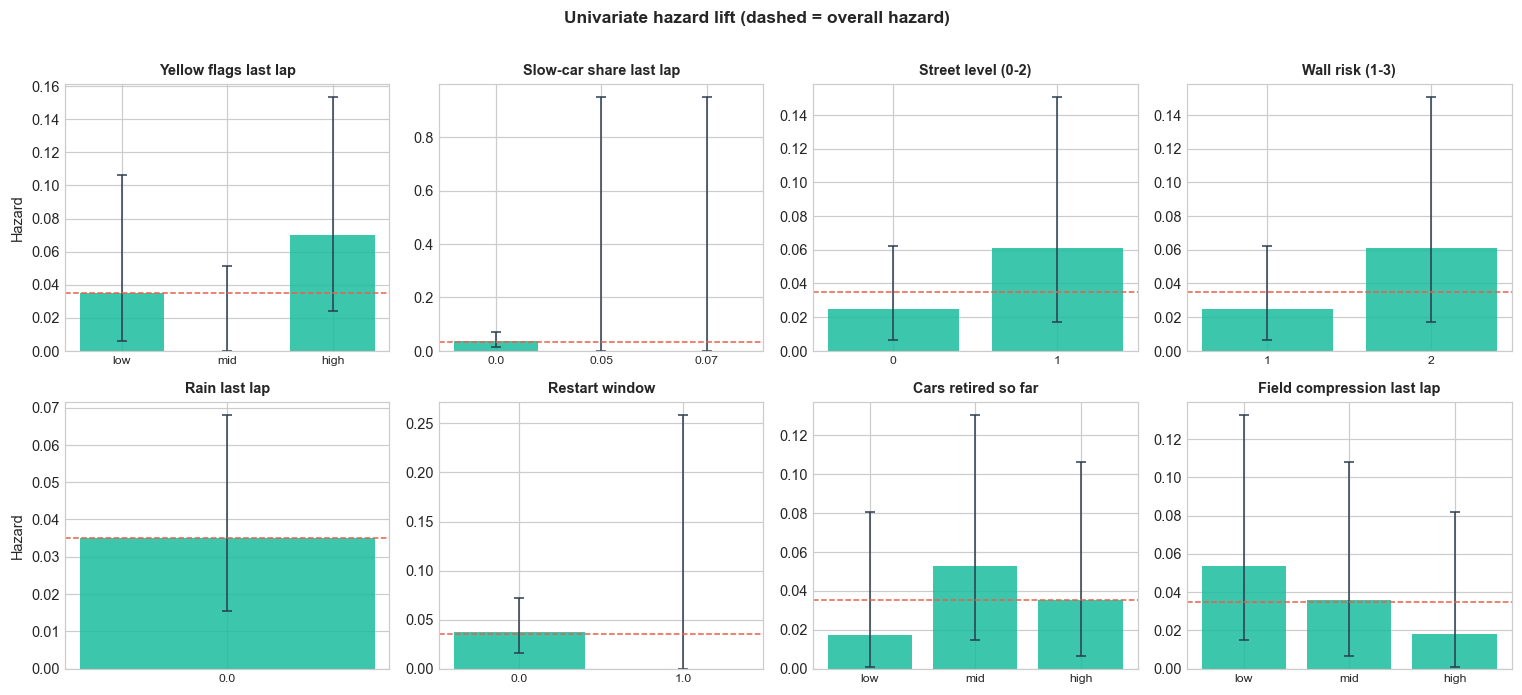

In [16]:
# ==============================================================================
# 6.4 Univariate lift of selected features
# ==============================================================================
show = [('yellow_prev', 'Yellow flags last lap'), ('slow_frac_prev', 'Slow-car share last lap'),
        ('street_level', 'Street level (0-2)'), ('wall_risk', 'Wall risk (1-3)'),
        ('rain_prev', 'Rain last lap'), ('restart_window', 'Restart window'),
        ('retired_prev', 'Cars retired so far'), ('compression_prev', 'Field compression last lap')]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
for ax, (col, ttl) in zip(axes.ravel(), show):
    s = TRAIN[col]
    if s.nunique() <= 4:
        grp = s.round(2)
    else:
        grp = pd.qcut(s.rank(method='first'), 3, labels=['low', 'mid', 'high'])
    t = TRAIN.assign(_g=grp).groupby('_g', observed=True)['y_any'].agg(['sum', 'count'])
    r = t['sum'] / t['count']
    ci = np.array([exact_ci(k, n) for k, n in zip(t['sum'], t['count'])])
    xs = np.arange(len(t))
    ax.bar(xs, r.values, color=PAL['teal'], alpha=0.85)
    ax.errorbar(xs, r.values, yerr=[np.maximum(r.values - ci[:, 0], 0), np.maximum(ci[:, 1] - r.values, 0)],
                fmt='none', ecolor=PAL['ink'], capsize=3, lw=1)
    ax.set_xticks(xs); ax.set_xticklabels([str(i) for i in t.index], fontsize=8)
    ax.set_title(ttl, fontsize=9.5); ax.axhline(TRAIN['y_any'].mean(), color=PAL['coral'], ls='--', lw=1)
axes[0, 0].set_ylabel('Hazard'); axes[1, 0].set_ylabel('Hazard')
plt.suptitle('Univariate hazard lift (dashed = overall hazard)' + TAG, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

## 7. Leakage-Safe Validation Strategy

| Choice | Why |
|---|---|
| **Leave-one-event-out (LOEO)** instead of a random split or Model 1's single `GroupShuffleSplit` | with only a few dozen onsets in total, one 25 % hold-out would contain a handful of events. LOEO uses every event as a test set exactly once → each lap gets an **out-of-fold (OOF)** hazard |
| **Whole races held out** | laps within a race share weather, circuit and incident history; random row splits would leak it |
| **Primary metric: log-loss / Brier**, AUC secondary | Model 3 consumes *probabilities*; ranking alone is not enough (technical document §3.4) |
| **Reference: climatology** | a constant per-lap hazard fitted on the training races. Brier Skill Score $=1-\text{Brier}/\text{Brier}_{\text{clim}}$ |
| **Event-level bootstrap** for all comparisons | laps are not independent; resampling *races* gives honest confidence intervals |
| **Parsimony rule** for model choice | pick the *simplest* model that is **not significantly worse** than the best one (paired event-bootstrap, 95 %) |

**Model families.** (i) a **regularised logistic hazard** (interpretable, stable when events are rare) built up group-by-group, which doubles as a forward ablation; (ii) **gradient-boosted trees** (HistGB / CatBoost / XGBoost if installed) with strong regularisation. Deep sequence models are *not* justified at this event count.

### 7.1 Runtime module (shared with Model 3 / Model 5)
The predictor class is written to `model4_sc_vsc.py` (same pattern as Model 2's `model2_tire_degradation.py`) so that pickled artefacts can be loaded from any notebook with `from model4_sc_vsc import Model4Predictor`. It carries the hazard model, the calibration shift, the bootstrap ensemble, the duration/type distributions and a **vectorised, state-aware Monte Carlo sampler**.

In [17]:
%%writefile model4_sc_vsc.py
"""StintIQ - Model 4 runtime: SC/VSC discrete-time hazard predictor (imported by Model 3 / Model 5)."""
import numpy as np
import pandas as pd
import joblib


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


class ConstantHazard:
    """Climatology baseline: one constant per-lap hazard."""
    def __init__(self):
        self.p_ = 0.0

    def fit(self, X, y):
        self.p_ = float(np.mean(y))
        return self

    def predict_proba(self, X):
        n = len(X)
        return np.column_stack([np.full(n, 1 - self.p_), np.full(n, self.p_)])


class Model4Predictor:
    """Calibrated discrete-time hazard h_t = P(new SC/VSC starts on lap t | none active, state at start of t).

    ctx keys used as scenario inputs (all optional except total_laps):
        total_laps, street_level, wall_risk, hist_sc_rate, rain_prev, wet_frac_prev,
        track_temp, air_temp, humidity, rain_change
    Incident / field features that are unknown in the future are held at their 'quiet-state' training medians.
    """

    def __init__(self, model, boot_models, features_all, shift, quiet,
                 dur_sc, dur_vsc, n_sc, n_vsc, pace_ratio=None, meta=None):
        self.model = model
        self.boot = list(boot_models or [])
        self.features_all = list(features_all)
        self.shift = float(shift)
        self.quiet = dict(quiet)
        self.dur_sc = np.asarray(dur_sc, dtype=int)
        self.dur_vsc = np.asarray(dur_vsc, dtype=int)
        self.n_sc, self.n_vsc = int(n_sc), int(n_vsc)
        self.pace_ratio = dict(pace_ratio or {})
        self.meta = dict(meta or {})

    # ------------------------------------------------------------------ core prediction
    def _predict(self, model, X):
        p = model.predict_proba(X)[:, 1]
        return _sigmoid(_logit(p) + self.shift)

    def hazard(self, X, with_band=False):
        p = self._predict(self.model, X)
        if not with_band or not self.boot:
            return p
        P = np.column_stack([self._predict(m, X) for m in self.boot])
        return p, np.percentile(P, 10, axis=1), np.percentile(P, 90, axis=1)

    def _make_X(self, ctx, t, since, n_prior):
        t = np.asarray(t, dtype=float)
        k = len(t)
        T = float(ctx['total_laps'])
        d = {c: np.full(k, self.quiet.get(c, np.nan), dtype=float) for c in self.features_all}
        for c in self.features_all:
            if c in ctx:
                d[c] = np.full(k, float(ctx[c]))
        since = np.minimum(np.asarray(since, dtype=float), 40)
        n_prior = np.asarray(n_prior, dtype=float)
        d['progress'] = t / T
        d['laps_remaining'] = T - t
        d['is_lap1'] = (t == 1).astype(float)
        d['laps_since_neut'] = since
        d['n_prior_neut'] = n_prior
        d['restart_window'] = ((n_prior > 0) & (since <= 2)).astype(float)
        return pd.DataFrame({c: d[c] for c in self.features_all})

    # ------------------------------------------------------------------ hazard curve for Model 3
    def hazard_curve(self, ctx, from_lap=1, last_neutral_lap=0, n_prior=0):
        """Per-lap hazard (+10/90 % bootstrap band) and cumulative P(first onset <= t), assuming nothing
        happens between from_lap and t (i.e. 'first event from now')."""
        T = int(ctx['total_laps'])
        laps = np.arange(int(from_lap), T + 1)
        since = (laps - 1) - last_neutral_lap
        X = self._make_X(ctx, laps, since, np.full(len(laps), n_prior))
        p, lo, hi = self.hazard(X, with_band=True) if self.boot else (self.hazard(X),) * 3
        return pd.DataFrame({
            'lap': laps, 'hazard': p, 'hazard_lo': lo, 'hazard_hi': hi,
            'cum_prob': 1 - np.cumprod(1 - p),
            'cum_lo': 1 - np.cumprod(1 - lo), 'cum_hi': 1 - np.cumprod(1 - hi)})

    @staticmethod
    def prob_within(curve, start_lap, horizon):
        """P(at least one onset in laps [start_lap, start_lap+horizon-1]) from a hazard_curve table."""
        m = (curve['lap'] >= start_lap) & (curve['lap'] < start_lap + horizon)
        return float(1 - np.prod(1 - curve.loc[m, 'hazard'].values)) if m.any() else np.nan

    # ------------------------------------------------------------------ Monte Carlo sampler for Model 3
    def _sample_dur(self, rng, kind, k):
        arr = self.dur_sc if kind == 'SC' else self.dur_vsc
        if len(arr) < 5:
            pooled = np.concatenate([self.dur_sc, self.dur_vsc])
            arr = pooled if len(pooled) >= 5 else np.array([4] if kind == 'SC' else [2])
        return rng.choice(arr, size=k)

    def simulate(self, ctx, n_sims=2000, rng=None, from_lap=1, last_neutral_lap=0, n_prior=0):
        """State-aware simulation of neutralisations. Parameter uncertainty is propagated: each simulated race
        uses one bootstrap hazard model and its own draw of P(SC | onset) ~ Beta posterior."""
        rng = rng or np.random.default_rng(0)
        T, n = int(ctx['total_laps']), int(n_sims)
        models = self.boot[:20] if self.boot else [self.model]
        G = len(models)
        gid = np.arange(n) % G
        p_sc = rng.beta(2 + self.n_sc, 2 + self.n_vsc, size=n)
        left = np.zeros(n, int)
        prev = np.zeros(n, bool)
        last_neut = np.full(n, last_neutral_lap)
        n_pri = np.full(n, n_prior)
        neutral = np.zeros((n, T + 1), bool)
        events = []
        for t in range(int(from_lap), T + 1):
            ongoing = left > 0
            risk = (~ongoing) & (~prev)
            h = np.zeros(n)
            for g in range(G):
                m = risk & (gid == g)
                if m.any():
                    X = self._make_X(ctx, np.full(m.sum(), t), (t - 1) - last_neut[m], n_pri[m])
                    h[m] = self._predict(models[g], X)
            new = risk & (rng.random(n) < h)
            if new.any():
                idx = np.where(new)[0]
                is_sc = rng.random(len(idx)) < p_sc[idx]
                dur = np.where(is_sc, self._sample_dur(rng, 'SC', len(idx)), self._sample_dur(rng, 'VSC', len(idx)))
                left[idx] = np.maximum(dur, 1)
                n_pri[idx] += 1
                events.extend((int(i), t, 'SC' if s else 'VSC', int(du)) for i, s, du in zip(idx, is_sc, dur))
            cur = left > 0
            neutral[cur, t] = True
            left[cur] -= 1
            last_neut[cur] = t
            prev = cur
        ev = pd.DataFrame(events, columns=['sim', 'lap', 'type', 'duration'])
        return {'events': ev, 'neutral': neutral[:, 1:], 'n_sims': n}

    # ------------------------------------------------------------------ persistence
    def save(self, path):
        joblib.dump(self, path)

    @staticmethod
    def load(path):
        return joblib.load(path)

Overwriting model4_sc_vsc.py


In [18]:
# ==============================================================================
# 7.2 Import the runtime module, build metric utilities and model factories
# ==============================================================================
importlib.invalidate_caches()
import model4_sc_vsc
importlib.reload(model4_sc_vsc)
from model4_sc_vsc import ConstantHazard, Model4Predictor

EPS = 1e-6
def clip_p(p): return np.clip(np.asarray(p, float), EPS, 1 - EPS)
def logloss(y, p): p = clip_p(p); return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
def per_row_ll(y, p): p = clip_p(p); return -(y * np.log(p) + (1 - y) * np.log(1 - p))
def safe_auc(y, p): return float(roc_auc_score(y, p)) if 0 < np.sum(y) < len(y) else np.nan

X_all = TRAIN[ALL_FEATURES].copy()
y_all = TRAIN['y_any'].values.astype(int)
ev_all = TRAIN['EventName'].values
G = FEATURE_GROUPS

def make_lr(cols, C):
    spl = [c for c in cols if c == 'progress']          # baseline hazard over race progress = spline
    oth = [c for c in cols if c != 'progress']
    tfs = []
    if spl:
        tfs.append(('spl', Pipeline([('imp', SimpleImputer(strategy='median')),
                                     ('s', SplineTransformer(n_knots=5, degree=3, extrapolation='constant'))]), spl))
    if oth:
        tfs.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), oth))
    return Pipeline([('prep', ColumnTransformer(tfs)),
                     ('clf', LogisticRegression(C=C, max_iter=3000))])

def make_gbt(kind, cols):
    pre = ColumnTransformer([('p', 'passthrough', cols)])
    if kind == 'HistGB':
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=120, l2_regularization=5.0,
                                             min_samples_leaf=40, random_state=RANDOM_STATE)
    elif kind == 'CatBoost':
        clf = cb.CatBoostClassifier(depth=3, iterations=250, learning_rate=0.03, l2_leaf_reg=10,
                                    random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False, thread_count=2)
    else:
        clf = xgb.XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, min_child_weight=3,
                                subsample=0.8, colsample_bytree=0.8, reg_lambda=10, random_state=RANDOM_STATE,
                                n_jobs=2, eval_metric='logloss')
    return Pipeline([('prep', pre), ('clf', clf)])

def loeo_oof(factory, X, y, ev):
    """Leave-one-event-out out-of-fold hazards."""
    oof = np.full(len(y), np.nan)
    for e in np.unique(ev):
        te = ev == e
        m = factory(); m.fit(X[~te], y[~te])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return oof

def event_bootstrap(p_a, p_b, y, ev, B=2000, seed=0):
    """Paired event-level bootstrap of  logloss(a) - logloss(b)  (negative => a better). Returns mean, (lo, hi)."""
    rng = np.random.default_rng(seed)
    ue = np.unique(ev)
    la = pd.Series(per_row_ll(y, p_a)).groupby(ev).sum().reindex(ue).values
    lb = pd.Series(per_row_ll(y, p_b)).groupby(ev).sum().reindex(ue).values
    n = pd.Series(np.ones(len(y))).groupby(ev).sum().reindex(ue).values
    idx = rng.integers(0, len(ue), (B, len(ue)))
    d = (la[idx].sum(1) - lb[idx].sum(1)) / n[idx].sum(1)
    return float(d.mean()), tuple(np.percentile(d, [2.5, 97.5]))

def event_bootstrap_se(p, y, ev, B=2000, seed=0):
    rng = np.random.default_rng(seed)
    ue = np.unique(ev)
    l = pd.Series(per_row_ll(y, p)).groupby(ev).sum().reindex(ue).values
    n = pd.Series(np.ones(len(y))).groupby(ev).sum().reindex(ue).values
    idx = rng.integers(0, len(ue), (B, len(ue)))
    return float(np.std(l[idx].sum(1) / n[idx].sum(1)))

print(f"Modelling table: {len(X_all):,} at-risk laps, {len(np.unique(ev_all))} events, {y_all.sum()} onsets, {len(ALL_FEATURES)} features")
if y_all.sum() < 15:
    print("[WARN] fewer than 15 onsets -> expect very noisy estimates; treat every number below as indicative only.")

Modelling table: 171 at-risk laps, 3 events, 6 onsets, 22 features
[WARN] fewer than 15 onsets -> expect very noisy estimates; treat every number below as indicative only.


### 7.3 Regularisation strength of the logistic hazard
With few events, **shrinkage is the main modelling decision**. The curve below sweeps the L2 strength $C$ (smaller = stronger shrinkage). Because $C$ is chosen on the same OOF predictions it is then evaluated on, the final log-loss is **slightly optimistic**; the sweep is wide and flat enough that this matters little, but it is disclosed here rather than hidden.

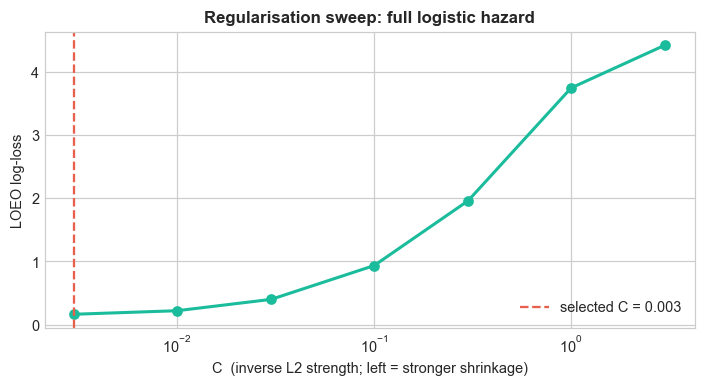

Selected C = 0.003


In [19]:
# ==============================================================================
# 7.3 C sensitivity (full feature set)
# ==============================================================================
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
sweep = []
for C in C_GRID:
    p = loeo_oof(lambda: make_lr(ALL_FEATURES, C), X_all, y_all, ev_all)
    sweep.append((C, logloss(y_all, p)))
sweep = pd.DataFrame(sweep, columns=['C', 'logloss'])
LR_C = float(sweep.loc[sweep['logloss'].idxmin(), 'C'])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogx(sweep['C'], sweep['logloss'], 'o-', color=PAL['teal'], lw=2)
ax.axvline(LR_C, color=PAL['coral'], ls='--', label=f'selected C = {LR_C:g}')
ax.set_xlabel('C  (inverse L2 strength; left = stronger shrinkage)'); ax.set_ylabel('LOEO log-loss')
ax.set_title('Regularisation sweep: full logistic hazard' + TAG); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Selected C = {LR_C:g}")

## 8. Model Benchmark

The logistic hazard is built **cumulatively** (time → + circuit → + weather → + incident → + field → + state). Each row therefore also acts as a forward ablation. Baselines: climatology (constant hazard) and the time-only hazard (the empirical shape from §6.2, smoothed).

In [20]:
# ==============================================================================
# 8.1 Registry of candidates -> LOEO OOF hazards -> comparison table
# ==============================================================================
def lr_factory(cols):
    cols = list(cols)
    return lambda: make_lr(cols, LR_C)

REGISTRY = {'Climatology': (lambda: ConstantHazard(), 0, 'baseline')}
labels = [('time', 'LR: time'), ('circuit', 'LR: +circuit'), ('weather', 'LR: +weather'),
          ('incident', 'LR: +incident'), ('field', 'LR: +field'), ('state', 'LR: +state (full)')]
cols_acc = []
for rank, (g, lab) in enumerate(labels, start=1):
    cols_acc = cols_acc + G[g]
    REGISTRY[lab] = (lr_factory(cols_acc), rank, 'logit')
gbt_kinds = ['HistGB'] + (['CatBoost'] if CATBOOST_AVAILABLE else []) + (['XGBoost'] if XGB_AVAILABLE else [])
for kind in gbt_kinds:
    REGISTRY[f'{kind}: full'] = ((lambda k=kind: make_gbt(k, ALL_FEATURES)), len(labels) + 1, 'gbt')

OOF = {}
t0 = time.time()
for name, (fac, rank, fam) in REGISTRY.items():
    OOF[name] = loeo_oof(fac, X_all, y_all, ev_all)
print(f"OOF predictions computed for {len(OOF)} models in {time.time() - t0:.1f}s")

brier_clim = brier_score_loss(y_all, clip_p(OOF['Climatology']))
ll_clim = logloss(y_all, OOF['Climatology'])
rows = []
for name, (fac, rank, fam) in REGISTRY.items():
    p = clip_p(OOF[name])
    d, (lo, hi) = event_bootstrap(p, OOF['Climatology'], y_all, ev_all)
    rows.append(dict(model=name, family=fam, rank=rank, logloss=logloss(y_all, p),
                     brier=brier_score_loss(y_all, p), auc=safe_auc(y_all, p),
                     BSS=1 - brier_score_loss(y_all, p) / brier_clim,
                     d_ll_vs_clim=d, d_lo=lo, d_hi=hi, se=event_bootstrap_se(p, y_all, ev_all)))
BENCH = pd.DataFrame(rows).sort_values('rank').reset_index(drop=True)

# One-standard-error rule: simplest model within 1 SE of the best log-loss
BENCH.loc[BENCH['family'] == 'baseline', 'auc'] = 0.5   # a constant hazard has no ranking skill by definition
cand = BENCH[BENCH['family'] != 'baseline'].copy()       # climatology is the reference, never the deployed hazard
best = cand.loc[cand['logloss'].idxmin()]
rel = []
for m in cand['model']:
    if m == best['model']:
        rel.append((m, 0.0, -np.inf)); continue
    d_, (lo_, hi_) = event_bootstrap(OOF[m], OOF[best['model']], y_all, ev_all)
    rel.append((m, d_, lo_))
rel = pd.DataFrame(rel, columns=['model', 'd_vs_best', 'lo_vs_best'])
eligible = cand.merge(rel, on='model')
eligible = eligible[eligible['lo_vs_best'] <= 0]          # not significantly worse than the best
PRIMARY = eligible.sort_values('rank').iloc[0]['model']
BENCH['selected'] = BENCH['model'] == PRIMARY

print("=" * 96)
print("BENCHMARK TABLE: MODEL 4 (LOEO out-of-fold)" + TAG)
print("=" * 96)
print(BENCH[['model', 'logloss', 'brier', 'auc', 'BSS', 'd_ll_vs_clim', 'd_lo', 'd_hi', 'selected']].round(4).to_string(index=False))
print(f"\nBest log-loss: {best['model']} ({best['logloss']:.4f}) | PRIMARY (simplest model not significantly worse than best): {PRIMARY}")

OOF predictions computed for 10 models in 1.1s
BENCHMARK TABLE: MODEL 4 (LOEO out-of-fold)
            model  logloss  brier    auc     BSS  d_ll_vs_clim    d_lo   d_hi  selected
      Climatology   0.1585 0.0343 0.5000  0.0000        0.0000  0.0000 0.0000     False
         LR: time   0.1586 0.0343 0.3152 -0.0000        0.0000 -0.0001 0.0002     False
     LR: +circuit   0.1585 0.0343 0.3141  0.0002       -0.0000 -0.0003 0.0002     False
     LR: +weather   0.1560 0.0342 0.3424  0.0042       -0.0026 -0.0079 0.0000      True
    LR: +incident   0.1625 0.0356 0.2899 -0.0372        0.0036 -0.0078 0.0158     False
       LR: +field   0.1625 0.0356 0.3040 -0.0374        0.0036 -0.0077 0.0158     False
LR: +state (full)   0.1626 0.0356 0.3141 -0.0387        0.0037 -0.0076 0.0161     False
     HistGB: full   0.1756 0.0347 0.3662 -0.0111        0.0180 -0.0139 0.0368     False
   CatBoost: full   0.2094 0.0551 0.6737 -0.6078        0.0477 -0.0336 0.1523     False
    XGBoost: full   0.1577 0.

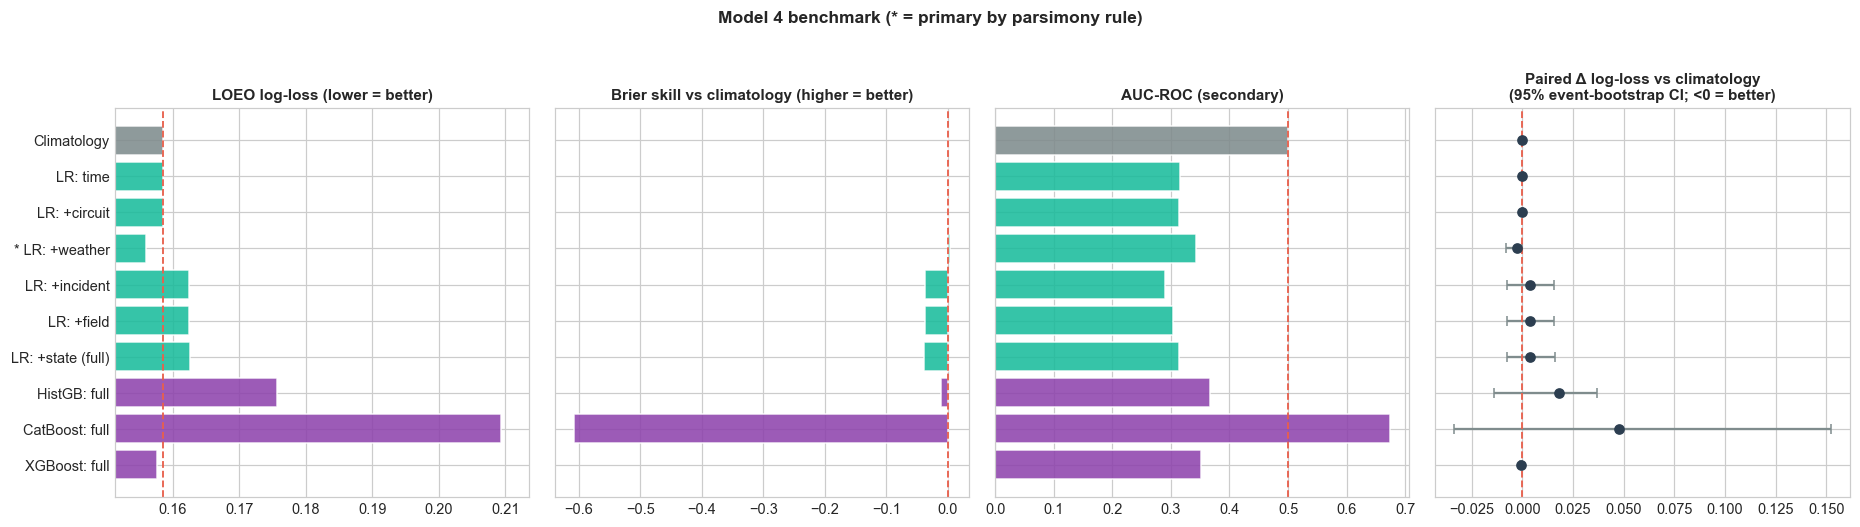

In [21]:
# ==============================================================================
# 8.2 Benchmark figure: log-loss, Brier skill, AUC, paired lift vs climatology
# ==============================================================================
colour = {'baseline': PAL['grey'], 'logit': PAL['teal'], 'gbt': PAL['purple']}
cs = [colour[f] for f in BENCH['family']]
yy = np.arange(len(BENCH))[::-1]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True)
for ax, (col, ttl) in zip(axes[:3], [('logloss', 'LOEO log-loss (lower = better)'), ('BSS', 'Brier skill vs climatology (higher = better)'),
                                      ('auc', 'AUC-ROC (secondary)')]):
    ax.barh(yy, BENCH[col], color=cs, alpha=0.88, edgecolor='white')
    ax.set_title(ttl, fontsize=10)
    if col == 'logloss': ax.axvline(ll_clim, color=PAL['coral'], ls='--', lw=1.2)
    if col == 'auc': ax.axvline(0.5, color=PAL['coral'], ls='--', lw=1.2)
    if col == 'BSS': ax.axvline(0, color=PAL['coral'], ls='--', lw=1.2)
    lo_lim = BENCH[col].min() * 0.97 if col == 'logloss' else None
    if lo_lim: ax.set_xlim(lo_lim, BENCH[col].max() * 1.02)
axes[0].set_yticks(yy); axes[0].set_yticklabels([('* ' if s else '') + m for m, s in zip(BENCH['model'], BENCH['selected'])])
ax = axes[3]
ax.errorbar(BENCH['d_ll_vs_clim'], yy, xerr=[BENCH['d_ll_vs_clim'] - BENCH['d_lo'], BENCH['d_hi'] - BENCH['d_ll_vs_clim']],
            fmt='o', color=PAL['ink'], ecolor=PAL['grey'], capsize=3)
ax.axvline(0, color=PAL['coral'], ls='--', lw=1.2)
ax.set_title('Paired Δ log-loss vs climatology\n(95% event-bootstrap CI; <0 = better)', fontsize=10)
plt.suptitle('Model 4 benchmark (* = primary by parsimony rule)' + TAG, fontweight='bold', y=1.03)
plt.tight_layout(); plt.show()

### 8.3 Ablation: which signal groups carry weight?
Left: the forward (cumulative) path from the benchmark table. Right: **leave-one-group-out** from the full logistic hazard. Error bars are 95 % paired event-bootstrap intervals; intervals that cross zero mean the group's contribution is **not distinguishable from noise** at the current event count.

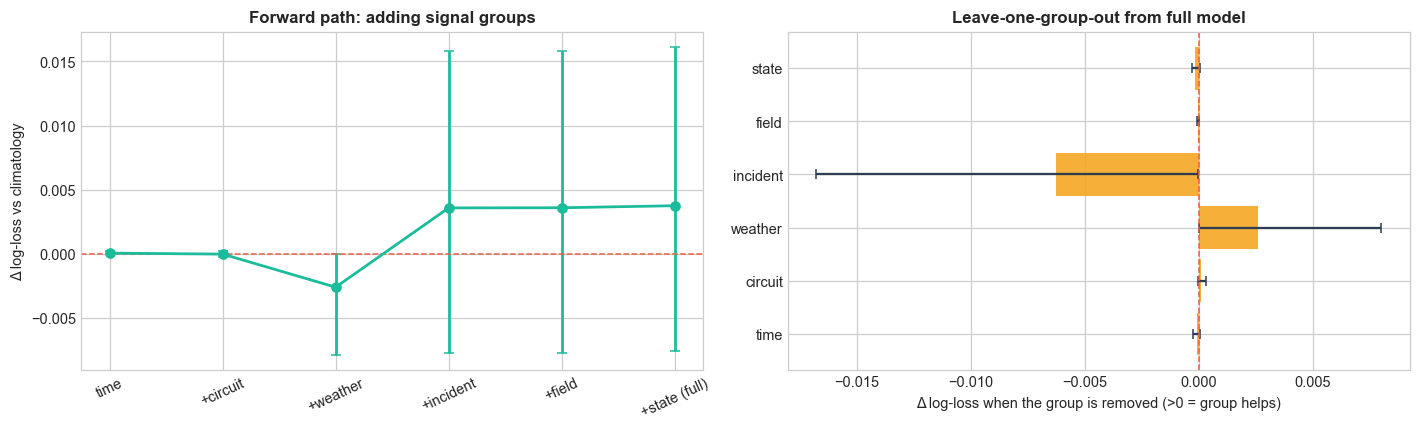

group_removed    d_ll      lo      hi
         time -0.0001 -0.0002  0.0000
      circuit  0.0001 -0.0000  0.0003
      weather  0.0026  0.0000  0.0080
     incident -0.0063 -0.0168 -0.0001
        field -0.0000 -0.0001  0.0000
        state -0.0002 -0.0003  0.0000


In [22]:
# ==============================================================================
# 8.3 Ablations
# ==============================================================================
p_full = clip_p(OOF['LR: +state (full)'])
abl = []
for g in G:
    cols = [c for c in ALL_FEATURES if c not in G[g]]
    p = loeo_oof(lambda cols=cols: make_lr(cols, LR_C), X_all, y_all, ev_all)
    d, (lo, hi) = event_bootstrap(p, p_full, y_all, ev_all)
    abl.append((g, d, lo, hi))
ABL = pd.DataFrame(abl, columns=['group_removed', 'd_ll', 'lo', 'hi'])      # >0 => removing the group HURTS

fwd = BENCH[BENCH['family'] == 'logit'].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.errorbar(range(len(fwd)), fwd['d_ll_vs_clim'], yerr=[fwd['d_ll_vs_clim'] - fwd['d_lo'], fwd['d_hi'] - fwd['d_ll_vs_clim']],
            fmt='o-', color=PAL['teal'], capsize=3, lw=1.8)
ax.axhline(0, color=PAL['coral'], ls='--', lw=1)
ax.set_xticks(range(len(fwd))); ax.set_xticklabels([m.replace('LR: ', '') for m in fwd['model']], rotation=25)
ax.set_ylabel('Δ log-loss vs climatology'); ax.set_title('Forward path: adding signal groups' + TAG)
ax = axes[1]
ax.barh(ABL['group_removed'], ABL['d_ll'], color=PAL['amber'], alpha=0.9)
ax.errorbar(ABL['d_ll'], range(len(ABL)), xerr=[ABL['d_ll'] - ABL['lo'], ABL['hi'] - ABL['d_ll']],
            fmt='none', ecolor=PAL['ink'], capsize=3)
ax.axvline(0, color=PAL['coral'], ls='--', lw=1)
ax.set_xlabel('Δ log-loss when the group is removed (>0 = group helps)'); ax.set_title('Leave-one-group-out from full model')
plt.tight_layout(); plt.show()
print(ABL.round(4).to_string(index=False))

## 9. Calibration & Diagnostics

> *"Prioritise calibration over raw accuracy. Feed the full hazard curve to Model 3."* — technical document, §3.4

A hazard that is 2× too high makes the optimiser over-value early "free" pit stops; one that is 2× too low makes it ignore real windows. Three checks: **reliability diagram**, **calibration slope/intercept**, and **race-level expected vs observed counts** (what Model 3 actually integrates). A single intercept shift (calibration-in-the-large) is applied if needed — one parameter, so it will not overfit a handful of events.

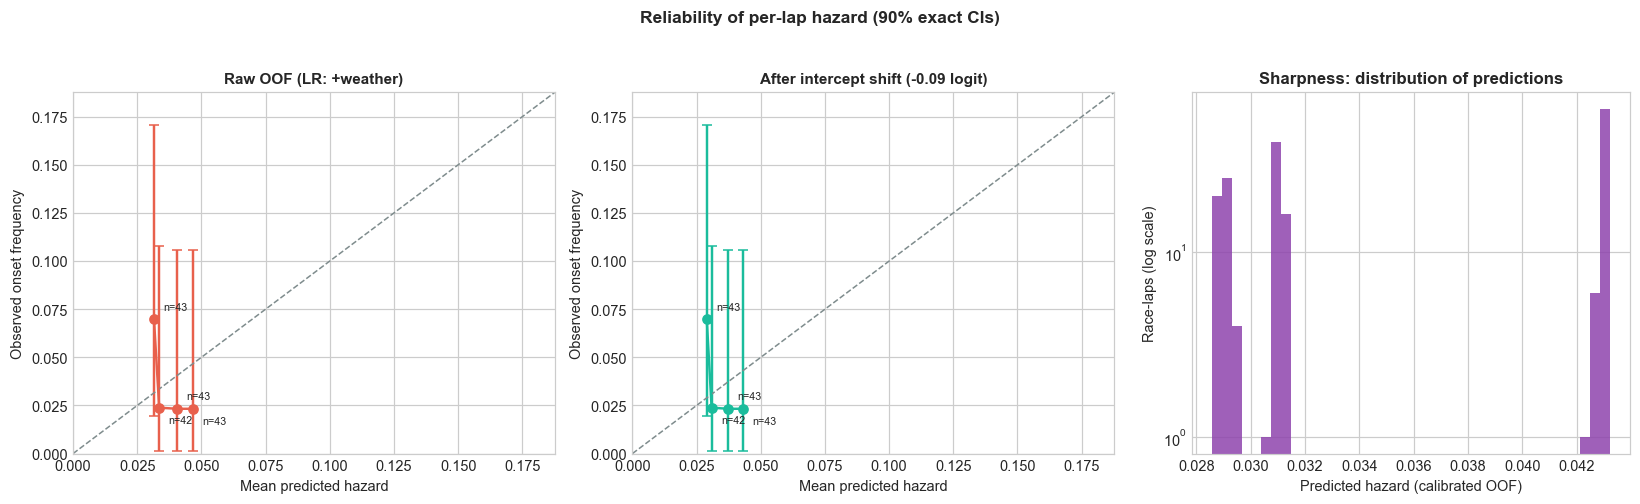

Calibration slope (ideal 1): -3.65 | calibration-in-the-large shift applied: -0.088 logit
Primary LR: +weather: log-loss raw 0.1560 -> calibrated 0.1559 | Brier raw 0.03415 -> calibrated 0.03412


In [23]:
# ==============================================================================
# 9.1 Reliability diagram + calibration-in-the-large for the PRIMARY model
# ==============================================================================
from scipy.optimize import brentq
def logit_(p): p = clip_p(p); return np.log(p / (1 - p))
def sigmoid_(z): return 1 / (1 + np.exp(-z))

p_oof = clip_p(OOF[PRIMARY])
def solve_shift(p, y):
    f = lambda b: sigmoid_(logit_(p) + b).mean() - y.mean()
    return float(brentq(f, -6, 6)) if f(-6) * f(6) < 0 else 0.0

SHIFT = solve_shift(p_oof, y_all)
p_cal = clip_p(sigmoid_(logit_(p_oof) + SHIFT))
slope_m = LogisticRegression(C=1e6, max_iter=1000).fit(logit_(p_oof).reshape(-1, 1), y_all)
cal_slope, cal_int = float(slope_m.coef_[0, 0]), float(slope_m.intercept_[0])

def reliability(y, p, n_bins=4):
    q = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.digitize(p, q[1:-1]), 0, len(q) - 2)
    out = []
    for i in range(len(q) - 1):
        m = b == i
        if m.sum() == 0: continue
        k, n = int(y[m].sum()), int(m.sum())
        lo, hi = exact_ci(k, n)
        out.append((p[m].mean(), k / n, lo, hi, n))
    return pd.DataFrame(out, columns=['pred', 'obs', 'lo', 'hi', 'n'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1.1, 1.1, 1]})
for ax, (p, ttl, c) in zip(axes[:2], [(p_oof, f'Raw OOF ({PRIMARY})', PAL['coral']), (p_cal, f'After intercept shift ({SHIFT:+.2f} logit)', PAL['teal'])]):
    R = reliability(y_all, p)
    lim = max(R['hi'].max(), R['pred'].max()) * 1.1
    ax.errorbar(R['pred'], R['obs'], yerr=[R['obs'] - R['lo'], R['hi'] - R['obs']], fmt='o-', color=c, capsize=3, lw=1.6)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.plot([0, lim], [0, lim], '--', color=PAL['grey'], lw=1)
    for j, (_, r) in enumerate(R.iterrows()):
        ax.annotate(f"n={int(r['n'])}", (r['pred'], r['obs']), fontsize=7, xytext=(6, -10 if j % 2 else 6), textcoords='offset points')
    ax.set_xlabel('Mean predicted hazard'); ax.set_ylabel('Observed onset frequency'); ax.set_title(ttl, fontsize=10)
ax = axes[2]
ax.hist(p_cal, bins=40, color=PAL['purple'], alpha=0.85)
ax.set_yscale('log'); ax.set_xlabel('Predicted hazard (calibrated OOF)'); ax.set_ylabel('Race-laps (log scale)')
ax.set_title('Sharpness: distribution of predictions')
plt.suptitle('Reliability of per-lap hazard (90% exact CIs)' + TAG, fontweight='bold', y=1.03)
plt.tight_layout(); plt.show()

print(f"Calibration slope (ideal 1): {cal_slope:.2f} | calibration-in-the-large shift applied: {SHIFT:+.3f} logit")
print(f"Primary {PRIMARY}: log-loss raw {logloss(y_all, p_oof):.4f} -> calibrated {logloss(y_all, p_cal):.4f} | "
      f"Brier raw {brier_score_loss(y_all, p_oof):.5f} -> calibrated {brier_score_loss(y_all, p_cal):.5f}")

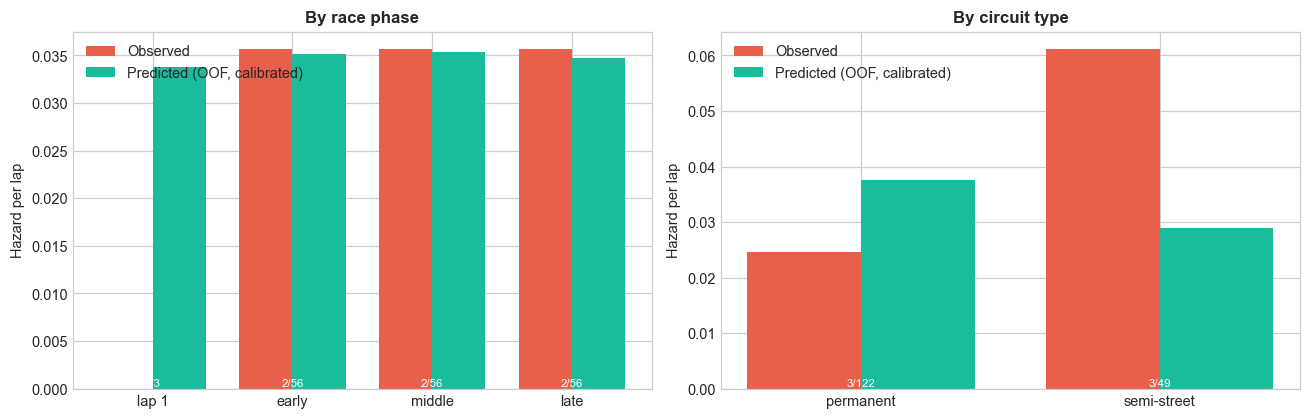

              laps  onsets  observed  predicted   brier
lap 1          3.0     0.0    0.0000     0.0338  0.0012
early         56.0     2.0    0.0357     0.0352  0.0349
middle        56.0     2.0    0.0357     0.0354  0.0349
late          56.0     2.0    0.0357     0.0347  0.0343
permanent    122.0     3.0    0.0246     0.0375  0.0243
semi-street   49.0     3.0    0.0612     0.0290  0.0586
street         NaN     NaN       NaN        NaN     NaN


In [24]:
# ==============================================================================
# 9.2 Breakdown by race phase and circuit type (technical-document requirement)
# ==============================================================================
D = TRAIN[['EventName', 'LapNumber', 'progress', 'street_level', 'y_any']].copy()
D['p'] = p_cal
D['phase'] = np.where(D['LapNumber'] == 1, 'lap 1', pd.cut(D['progress'], [0, 1 / 3, 2 / 3, 1.0], labels=['early', 'middle', 'late'], include_lowest=True).astype(str))
D['circuit_type'] = D['street_level'].map({0: 'permanent', 1: 'semi-street', 2: 'street'})

def breakdown(by):
    t = D.groupby(by).apply(lambda g: pd.Series({'laps': len(g), 'onsets': int(g['y_any'].sum()),
                                                  'observed': g['y_any'].mean(), 'predicted': g['p'].mean(),
                                                  'brier': brier_score_loss(g['y_any'], g['p'])}))
    return t

ph = breakdown('phase').reindex(['lap 1', 'early', 'middle', 'late'])
ct = breakdown('circuit_type').reindex(['permanent', 'semi-street', 'street'])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, t, ttl in [(axes[0], ph, 'By race phase'), (axes[1], ct, 'By circuit type')]:
    t = t.dropna()
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w / 2, t['observed'], w, color=PAL['coral'], label='Observed')
    ax.bar(x + w / 2, t['predicted'], w, color=PAL['teal'], label='Predicted (OOF, calibrated)')
    for i, (k, n) in enumerate(zip(t['onsets'], t['laps'])): ax.text(i, 0, f"{int(k)}/{int(n)}", ha='center', va='bottom', fontsize=7.5, color='white')
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_title(ttl + TAG); ax.set_ylabel('Hazard per lap'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(pd.concat([ph, ct]).round(4).to_string())

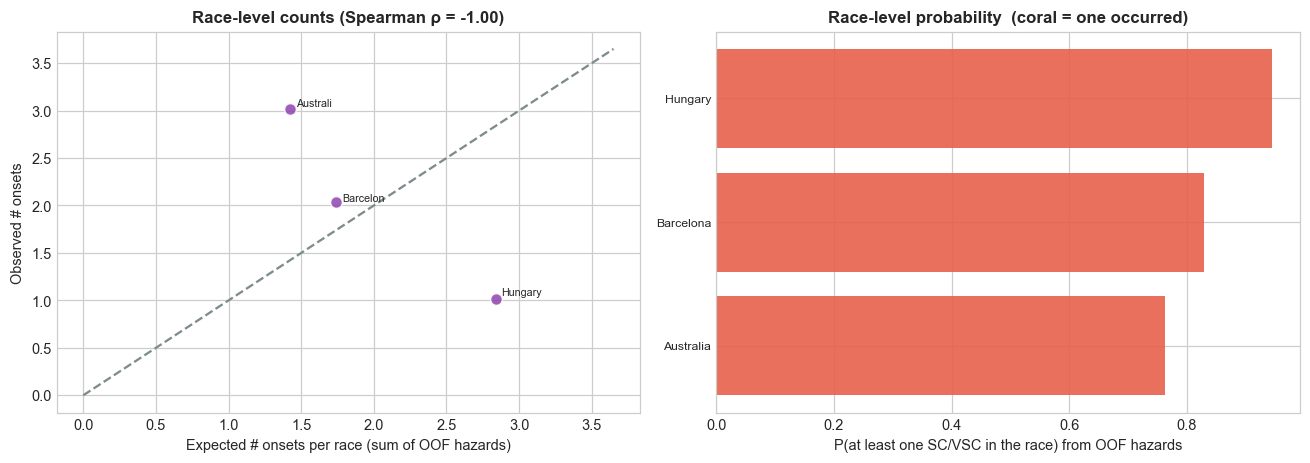

Mean predicted P(>=1 neutralisation / race) = 0.85 | observed share of races with one = 1.00


In [25]:
# ==============================================================================
# 9.3 Race-level calibration: expected vs observed neutralisations (what Model 3 integrates)
# ==============================================================================
rl = D.groupby('EventName').agg(expected=('p', 'sum'), observed=('y_any', 'sum'),
                                p_any=('p', lambda s: 1 - np.prod(1 - s.values)))
rl['any_obs'] = (rl['observed'] > 0).astype(int)
rho = stats.spearmanr(rl['expected'], rl['observed'])[0] if rl['observed'].nunique() > 1 else np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
lim = max(rl['expected'].max(), rl['observed'].max()) * 1.15 + 0.2
ax.plot([0, lim], [0, lim], '--', color=PAL['grey'])
jitter = np.random.default_rng(1).normal(0, 0.04, len(rl))
ax.scatter(rl['expected'], rl['observed'] + jitter, s=60, color=PAL['purple'], alpha=0.85, edgecolor='white')
for ev_, r in rl.iterrows(): ax.annotate(ev_.split('_', 1)[-1][:8], (r['expected'], r['observed']), fontsize=7, xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('Expected # onsets per race (sum of OOF hazards)'); ax.set_ylabel('Observed # onsets')
ax.set_title(f'Race-level counts (Spearman ρ = {rho:.2f})' + TAG)
ax = axes[1]
R2 = rl.sort_values('p_any')
cols_ = [PAL['coral'] if o else PAL['teal'] for o in R2['any_obs']]
ax.barh(range(len(R2)), R2['p_any'], color=cols_, alpha=0.9)
ax.set_yticks(range(len(R2))); ax.set_yticklabels([e.split('_', 1)[-1] for e in R2.index], fontsize=8)
ax.set_xlabel('P(at least one SC/VSC in the race) from OOF hazards'); ax.set_title('Race-level probability  (coral = one occurred)')
plt.tight_layout(); plt.show()
print(f"Mean predicted P(>=1 neutralisation / race) = {rl['p_any'].mean():.2f} | observed share of races with one = {rl['any_obs'].mean():.2f}")

## 10. Final Model, Uncertainty Band and Model 3 Hand-off

Steps: (1) refit the primary hazard on **all** reliable events, (2) build an **event-level bootstrap ensemble** so Model 3 receives a hazard *band*, not a point, (3) package everything — model, calibration shift, bootstrap ensemble, duration and type distributions, pace-under-neutralisation — into `Model4Predictor`.

> *"Do not reduce Models 1/2/4 to point estimates before simulation."* — technical document, §9

In [26]:
# ==============================================================================
# 10.1 Final fit + bootstrap ensemble + predictor packaging
# ==============================================================================
def bootstrap_models(factory, X, y, ev, B=60, seed=0, exclude=None):
    """Event-level (cluster) bootstrap: resample whole races with replacement."""
    rng = np.random.default_rng(seed)
    ue = np.unique(ev if exclude is None else ev[ev != exclude])
    models = []
    while len(models) < B:
        pick = rng.choice(ue, size=len(ue), replace=True)
        idx = np.concatenate([np.where(ev == e)[0] for e in pick])
        if y[idx].sum() == 0:
            continue
        m = factory(); m.fit(X.iloc[idx], y[idx]); models.append(m)
    return models

B_BOOT = 60
FINAL_FACTORY = REGISTRY[PRIMARY][0]
final_model = FINAL_FACTORY().fit(X_all, y_all)
t0 = time.time()
boot_models = bootstrap_models(FINAL_FACTORY, X_all, y_all, ev_all, B=B_BOOT, seed=RANDOM_STATE)
print(f"Primary model: {PRIMARY} | {B_BOOT} event-bootstrap refits in {time.time() - t0:.1f}s | calibration shift {SHIFT:+.3f} logit")

QUIET = X_all.median(numeric_only=True).to_dict()          # 'nothing unusual happening' state for unknown future signals
dur_sc = EPISODES.loc[EPISODES['type'] == 'SC', 'duration'].values
dur_vsc = EPISODES.loc[EPISODES['type'] == 'VSC', 'duration'].values
pace_ratio = {}
for s in ['SC', 'VSC']:
    v = LAP.loc[(LAP['status'] == s) & LAP['label_reliable'] & LAP['ratio_med'].notna(), 'ratio_med']
    pace_ratio[s] = {'median': float(v.median()), 'q10': float(v.quantile(0.1)), 'q90': float(v.quantile(0.9)), 'n': int(len(v))} if len(v) else None

best_row = BENCH.loc[BENCH['model'] == PRIMARY].iloc[0]
META = dict(primary_model=PRIMARY, lr_C=LR_C, calibration_shift=SHIFT, calibration_slope=cal_slope,
            n_events=int(len(np.unique(ev_all))), n_onsets=int(y_all.sum()), n_at_risk_laps=int(len(y_all)),
            loeo_logloss=float(best_row['logloss']), loeo_brier=float(best_row['brier']),
            loeo_auc=None if np.isnan(best_row['auc']) else float(best_row['auc']), loeo_bss=float(best_row['BSS']),
            features=ALL_FEATURES, feature_groups=FEATURE_GROUPS, synthetic_data=bool(SYNTHETIC),
            status_min_frac=STATUS_MIN_FRAC, created=time.strftime('%Y-%m-%d %H:%M:%S'))

predictor = Model4Predictor(model=final_model, boot_models=boot_models, features_all=ALL_FEATURES, shift=SHIFT,
                            quiet=QUIET, dur_sc=dur_sc, dur_vsc=dur_vsc,
                            n_sc=int((EPISODES['type'] == 'SC').sum()), n_vsc=int((EPISODES['type'] == 'VSC').sum()),
                            pace_ratio=pace_ratio, meta=META)
predictor.save(MODELS_DIR / 'model4_sc_vsc.joblib')
print(f"Saved predictor -> {MODELS_DIR / 'model4_sc_vsc.joblib'}")

Primary model: LR: +weather | 60 event-bootstrap refits in 0.2s | calibration shift -0.088 logit
Saved predictor -> /Users/hemant/Work/StintIQ/Model Development/models/model4_sc_vsc.joblib


### 10.2 What drives the hazard? (interpretable logistic view)
Standardised logistic coefficients with **event-bootstrap 95 % intervals** (200 resamples). Spline terms for race progress are shown separately as the baseline hazard curve below. Coefficients whose intervals cross zero are not reliable drivers at the current sample size, regardless of what a tree model's importance ranking would suggest.

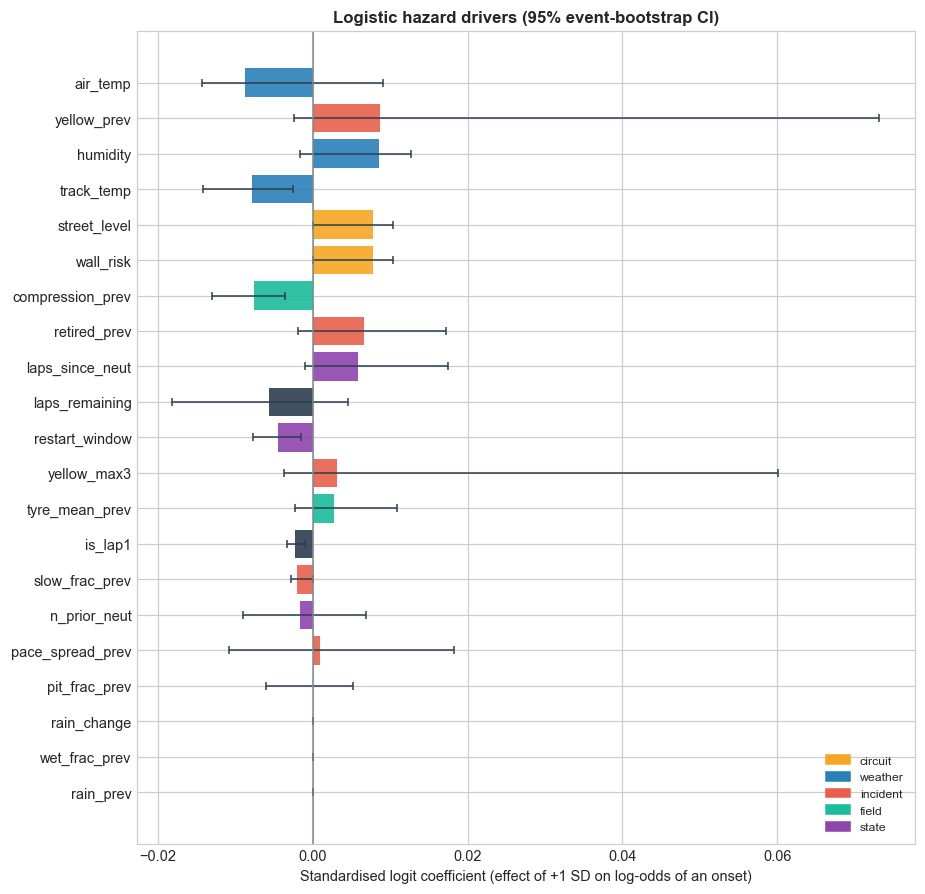

Coefficients whose 95% interval excludes 0: ['is_lap1', 'restart_window', 'compression_prev', 'track_temp']


In [27]:
# ==============================================================================
# 10.2 Coefficients with bootstrap intervals (logistic view, regardless of the primary model)
# ==============================================================================
lr_cols = [c for c in ALL_FEATURES if c != 'progress']
lr_boot = bootstrap_models(lr_factory(ALL_FEATURES), X_all, y_all, ev_all, B=200, seed=7)
lr_main = lr_factory(ALL_FEATURES)().fit(X_all, y_all)
def num_coef(m): return m.named_steps['clf'].coef_[0][-len(lr_cols):]
coef = pd.DataFrame({'feature': lr_cols, 'coef': num_coef(lr_main)})
B_ = np.vstack([num_coef(m) for m in lr_boot])
coef['lo'], coef['hi'] = np.percentile(B_, 2.5, axis=0), np.percentile(B_, 97.5, axis=0)
grp_of = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
gcol = dict(time=PAL['ink'], circuit=PAL['amber'], weather=PAL['blue'], incident=PAL['coral'], field=PAL['teal'], state=PAL['purple'])
coef['group'] = coef['feature'].map(grp_of)
coef = coef.reindex(coef['coef'].abs().sort_values().index)

fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(coef) + 1.5))
ax.barh(coef['feature'], coef['coef'], color=[gcol[g] for g in coef['group']], alpha=0.9)
ax.errorbar(coef['coef'], range(len(coef)), xerr=[coef['coef'] - coef['lo'], coef['hi'] - coef['coef']],
            fmt='none', ecolor=PAL['ink'], capsize=2.5, lw=1)
ax.axvline(0, color=PAL['grey'], lw=1)
ax.set_xlabel('Standardised logit coefficient (effect of +1 SD on log-odds of an onset)')
ax.set_title('Logistic hazard drivers (95% event-bootstrap CI)' + TAG)
ax.legend(handles=[mpatches.Patch(color=c, label=g) for g, c in gcol.items() if g != 'time'], frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()
sig = coef[(coef['lo'] > 0) | (coef['hi'] < 0)]['feature'].tolist()
print("Coefficients whose 95% interval excludes 0:", sig or "none")

### 10.3 Hazard and cumulative-probability curves (the object Model 3 consumes)
**Left:** out-of-fold hazard for one held-out race with its 10–90 % bootstrap band (model trained *without* that race), plotted against what actually happened. **Right:** the pre-race forecast `P(at least one SC/VSC by lap t)` built only from circuit and weather, via `predictor.hazard_curve`.

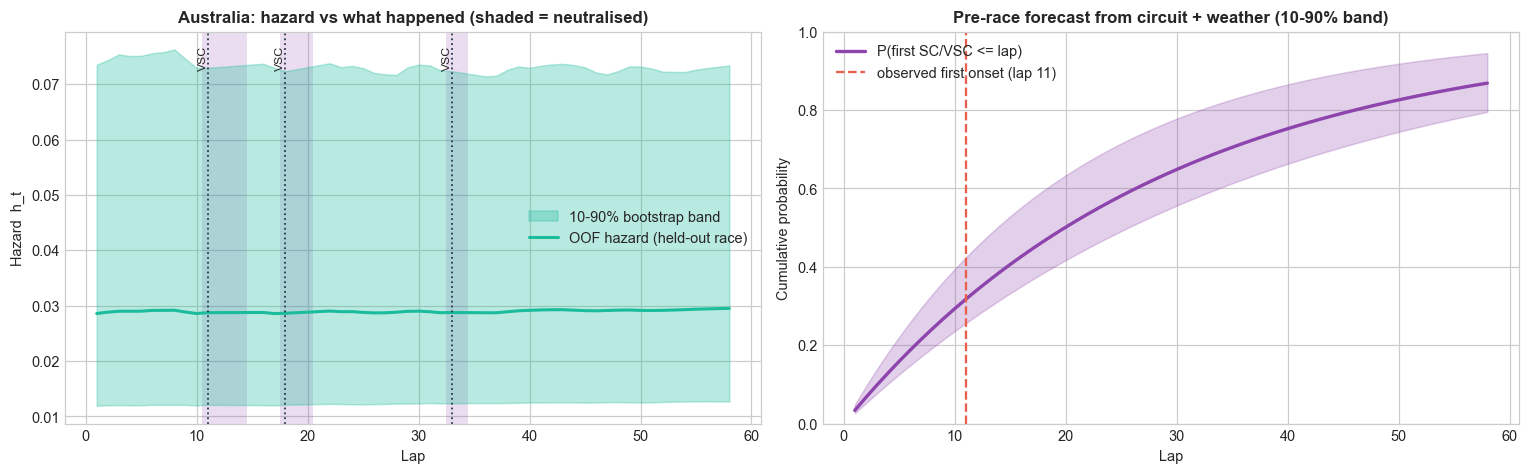

Pre-race P(>=1 SC/VSC in 58 laps) = 0.87 [0.80, 0.94]


In [28]:
# ==============================================================================
# 10.4 Demo race: OOF hazard + band, and pre-race cumulative curve
# ==============================================================================
def ctx_from_event(ev, wet=False, **override):
    e = LAP[(LAP['EventName'] == ev) & LAP['has_data']].sort_values('LapNumber')
    r = e.iloc[1] if len(e) > 1 else e.iloc[0]
    ctx = dict(total_laps=int(r['TotalLaps']), street_level=float(r['street_level']), wall_risk=float(r['wall_risk']),
               rain_prev=float(r['rain_prev']), wet_frac_prev=float(r['wet_frac_prev']), track_temp=float(r['track_temp']),
               air_temp=float(r['air_temp']), humidity=float(r['humidity']), rain_change=0.0)
    if 'hist_sc_rate' in e.columns: ctx['hist_sc_rate'] = float(r['hist_sc_rate'])
    if wet: ctx.update(rain_prev=1.0, wet_frac_prev=1.0, humidity=max(ctx['humidity'], 75.0))
    ctx.update(override)
    return ctx

onset_counts = TRAIN.groupby('EventName')['y_any'].sum()
DEMO_EVENT = onset_counts.sort_values(ascending=False).index[0]           # edit to inspect any other race
dm = TRAIN['EventName'] == DEMO_EVENT
Xd = X_all[dm.values]
dem_boot = bootstrap_models(FINAL_FACTORY, X_all, y_all, ev_all, B=40, seed=3, exclude=DEMO_EVENT)
Pb = np.column_stack([sigmoid_(logit_(m.predict_proba(Xd)[:, 1]) + SHIFT) for m in dem_boot])
lo_d, hi_d = np.percentile(Pb, 10, axis=1), np.percentile(Pb, 90, axis=1)
p_d = p_cal[dm.values]
laps_d = TRAIN.loc[dm, 'LapNumber'].values

full = LAP[(LAP['EventName'] == DEMO_EVENT) & LAP['has_data']]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
for _, r in full.iterrows():
    if r['status'] == 'SC':  ax.axvspan(r['LapNumber'] - 0.5, r['LapNumber'] + 0.5, color=PAL['coral'], alpha=0.18, lw=0)
    if r['status'] == 'VSC': ax.axvspan(r['LapNumber'] - 0.5, r['LapNumber'] + 0.5, color=PAL['purple'], alpha=0.18, lw=0)
ax.fill_between(laps_d, lo_d, hi_d, color=PAL['teal'], alpha=0.3, label='10-90% bootstrap band')
ax.plot(laps_d, p_d, color=PAL['teal'], lw=2, label='OOF hazard (held-out race)')
for _, r in full[full['onset']].iterrows():
    ax.axvline(r['LapNumber'], color=PAL['ink'], ls=':', lw=1.2)
    ax.text(r['LapNumber'], ax.get_ylim()[1] * 0.97, r['onset_type'], rotation=90, va='top', ha='right', fontsize=8)
ax.set_xlabel('Lap'); ax.set_ylabel('Hazard  h_t'); ax.set_title(f"{DEMO_EVENT.split('_', 1)[-1]}: hazard vs what happened (shaded = neutralised)" + TAG)
ax.legend(frameon=False, loc='center right')

ctx_demo = ctx_from_event(DEMO_EVENT)
curve = predictor.hazard_curve(ctx_demo, from_lap=1)
ax = axes[1]
ax.fill_between(curve['lap'], curve['cum_lo'], curve['cum_hi'], color=PAL['purple'], alpha=0.25)
ax.plot(curve['lap'], curve['cum_prob'], color=PAL['purple'], lw=2.2, label='P(first SC/VSC <= lap)')
first_on = full.loc[full['onset'], 'LapNumber'].min()
if pd.notna(first_on): ax.axvline(first_on, color=PAL['coral'], ls='--', label=f'observed first onset (lap {int(first_on)})')
ax.set_ylim(0, 1); ax.set_xlabel('Lap'); ax.set_ylabel('Cumulative probability')
ax.set_title('Pre-race forecast from circuit + weather (10-90% band)' + TAG); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()
print(f"Pre-race P(>=1 SC/VSC in {ctx_demo['total_laps']} laps) = {curve['cum_prob'].iloc[-1]:.2f} "
      f"[{curve['cum_lo'].iloc[-1]:.2f}, {curve['cum_hi'].iloc[-1]:.2f}]")

### 10.5 Scenario comparison and the pit-decision window
Model 3 asks *"if I wait k more laps, how likely is a neutralisation?"*. Left: how the pre-race cumulative curve changes with circuit type and rain. Right: **P(neutralisation within the next k laps)** as a function of the current lap — the quantity a strategist compares against the pit-stop cost.

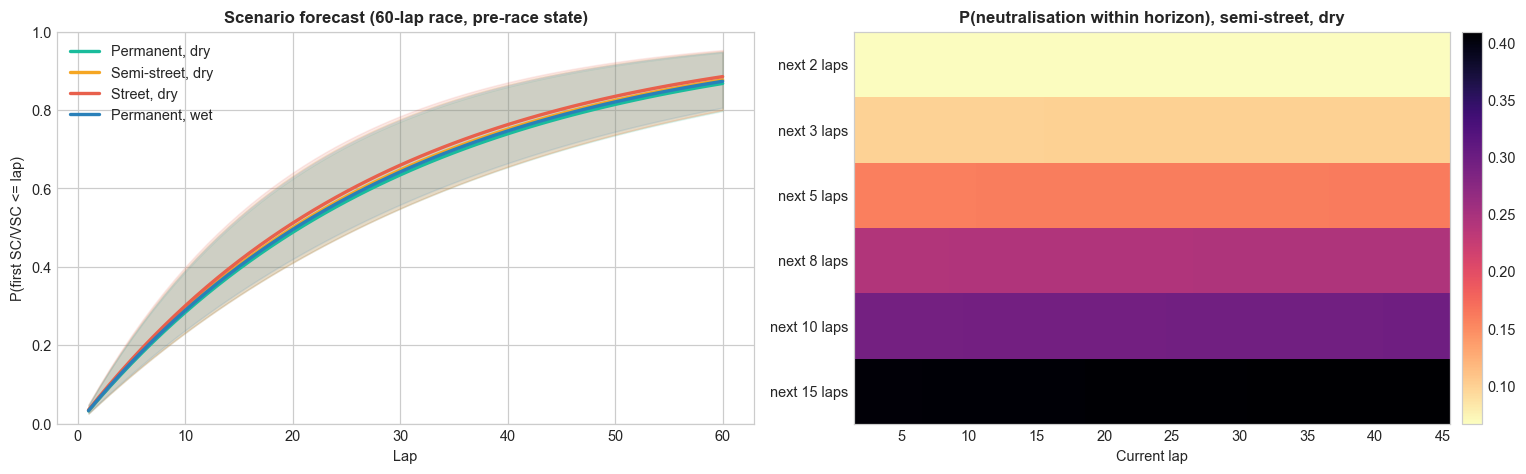

A very wide band (e.g. the wet scenario) means few training laps resemble that scenario: treat it as unsupported, not as a forecast.


In [29]:
# ==============================================================================
# 10.5 Scenario curves and pit-decision window heat-map
# ==============================================================================
base_ctx = dict(ctx_demo, total_laps=60)
scen = {'Permanent, dry': dict(street_level=0.0, wall_risk=1.0),
        'Semi-street, dry': dict(street_level=1.0, wall_risk=2.0),
        'Street, dry': dict(street_level=2.0, wall_risk=3.0),
        'Permanent, wet': dict(street_level=0.0, wall_risk=1.0, rain_prev=1.0, wet_frac_prev=1.0, humidity=80.0)}
scol = [PAL['teal'], PAL['amber'], PAL['coral'], PAL['blue']]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
for (name, upd), c in zip(scen.items(), scol):
    cu = predictor.hazard_curve(dict(base_ctx, rain_prev=0.0, wet_frac_prev=0.0, humidity=50.0, **upd) if 'wet' not in name else dict(base_ctx, **upd))
    ax.plot(cu['lap'], cu['cum_prob'], lw=2.2, color=c, label=name)
    ax.fill_between(cu['lap'], cu['cum_lo'], cu['cum_hi'], color=c, alpha=0.12)
ax.set_ylim(0, 1); ax.set_xlabel('Lap'); ax.set_ylabel('P(first SC/VSC <= lap)')
ax.set_title('Scenario forecast (60-lap race, pre-race state)' + TAG); ax.legend(frameon=False)

horizons = [2, 3, 5, 8, 10, 15]
cu = predictor.hazard_curve(dict(base_ctx, rain_prev=0.0, wet_frac_prev=0.0, humidity=50.0, **scen['Semi-street, dry']))
starts = np.arange(2, 46)          # keep start + longest horizon inside the race
Hm = np.array([[predictor.prob_within(cu, s, k) for s in starts] for k in horizons])
ax = axes[1]
im = ax.imshow(Hm, aspect='auto', cmap='magma_r', extent=[starts[0] - 0.5, starts[-1] + 0.5, len(horizons) - 0.5, -0.5])
ax.set_yticks(range(len(horizons))); ax.set_yticklabels([f"next {k} laps" for k in horizons])
ax.set_xlabel('Current lap'); ax.set_title('P(neutralisation within horizon), semi-street, dry')
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02); ax.grid(False)
plt.tight_layout(); plt.show()
print('A very wide band (e.g. the wet scenario) means few training laps resemble that scenario: treat it as unsupported, not as a forecast.')

### 10.6 Monte Carlo sampling for Model 3 (parameter uncertainty propagated)
`predictor.simulate` is **state-aware**: after a simulated SC, the next lap is not at risk and the restart-window / laps-since-neutralisation features change, so several events can occur in one race. Every simulated race uses its own bootstrap hazard model and its own draw of P(SC | onset), and durations are resampled from the observed episode lengths.

Simulated 3000 races x 58 laps in 1.7s


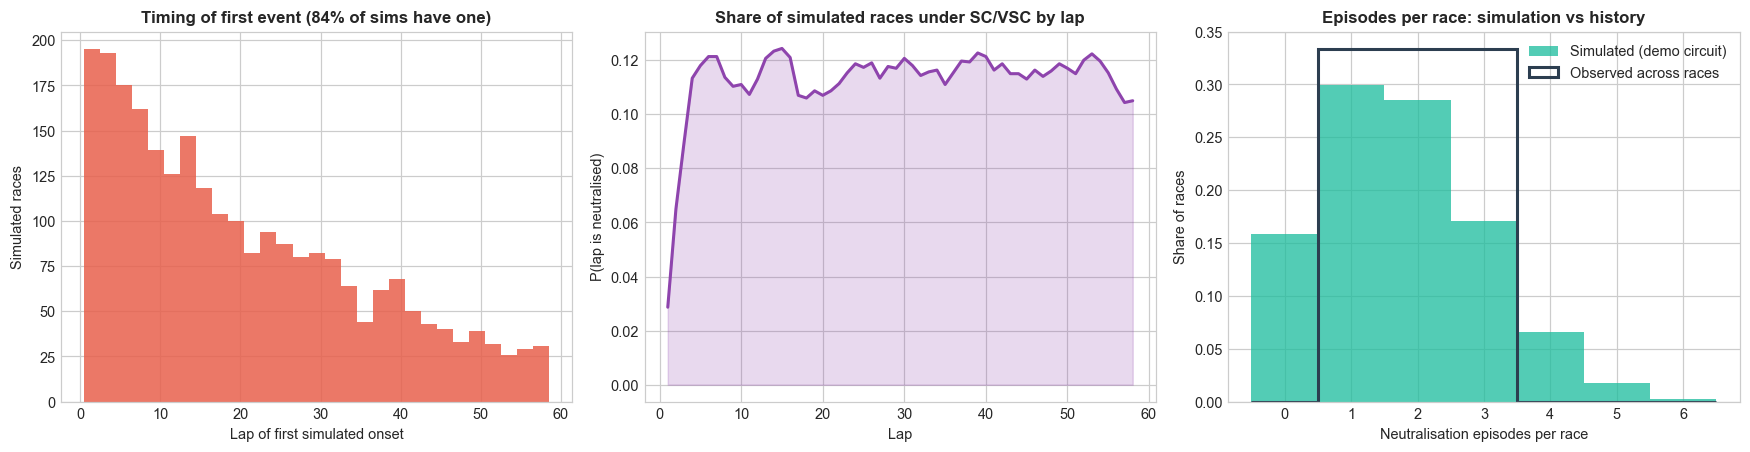

Mean episodes/race: simulated 1.75 | observed 2.00  (simulated race uses ONE circuit/weather scenario; observed pools all races)
Type split in simulation: {'VSC': 0.8, 'SC': 0.2} | observed: {'VSC': 1.0}


In [30]:
# ==============================================================================
# 10.6 Simulation demo vs observed history
# ==============================================================================
t0 = time.time()
sim = predictor.simulate(ctx_demo, n_sims=3000, rng=np.random.default_rng(RANDOM_STATE))
print(f"Simulated 3000 races x {ctx_demo['total_laps']} laps in {time.time() - t0:.1f}s")
ev_sim, neutral_sim = sim['events'], sim['neutral']
n_ep_sim = ev_sim.groupby('sim').size().reindex(range(sim['n_sims'])).fillna(0).astype(int)
n_ep_obs = EPISODES.groupby('EventName').size().reindex(sorted(LAP.loc[LAP['label_reliable'], 'EventName'].unique())).fillna(0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
first = ev_sim.groupby('sim')['lap'].min()
ax.hist(first, bins=np.arange(0.5, ctx_demo['total_laps'] + 1.5, 2), color=PAL['coral'], alpha=0.85)
ax.set_xlabel('Lap of first simulated onset'); ax.set_ylabel('Simulated races')
ax.set_title(f"Timing of first event ({len(first) / sim['n_sims']:.0%} of sims have one)" + TAG)
ax = axes[1]
laps_ax = np.arange(1, ctx_demo['total_laps'] + 1)
ax.plot(laps_ax, neutral_sim.mean(0), color=PAL['purple'], lw=2)
ax.fill_between(laps_ax, 0, neutral_sim.mean(0), color=PAL['purple'], alpha=0.2)
ax.set_xlabel('Lap'); ax.set_ylabel('P(lap is neutralised)'); ax.set_title('Share of simulated races under SC/VSC by lap')
ax = axes[2]
mx = int(max(n_ep_sim.max(), n_ep_obs.max(), 3))
bins = np.arange(-0.5, mx + 1.5, 1)
ax.hist(n_ep_sim, bins=bins, density=True, color=PAL['teal'], alpha=0.75, label='Simulated (demo circuit)')
ax.hist(n_ep_obs, bins=bins, density=True, histtype='step', color=PAL['ink'], lw=2, label='Observed across races')
ax.set_xlabel('Neutralisation episodes per race'); ax.set_ylabel('Share of races'); ax.set_title('Episodes per race: simulation vs history')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Mean episodes/race: simulated {n_ep_sim.mean():.2f} | observed {n_ep_obs.mean():.2f}  (simulated race uses ONE circuit/weather scenario; observed pools all races)")
print("Type split in simulation:", ev_sim['type'].value_counts(normalize=True).round(2).to_dict(), "| observed:", EPISODES['type'].value_counts(normalize=True).round(2).to_dict())

## 11. Artefacts and Integration

### 11.1 How Model 4 connects to the rest of StintIQ

| Direction | Interface | Notes |
|---|---|---|
| **Raw data → Model 4** | `lap_data_raw.csv` (same file as Model 1) | keys `EventName`, `LapNumber`, `Driver`; same `TotalLaps`, `TyreLife`, weather columns |
| **Model 4 → Model 1** | `lap_status_table.csv` | one neutralisation definition for both models; replaces the inline `TrackStatus == '1'` filter in Model 1 §5 |
| **Model 1 → Model 4** (optional) | `model1_oof_predictions.csv` | out-of-fold Model 1 residuals give a pace-anomaly feature that replaces the model-free `slow_frac_prev` |
| **Model 4 → Model 3** | `Model4Predictor.hazard_curve / simulate` | hazard + band, sampled onset lap, type and duration; SC/VSC pace multipliers in `predictor.pace_ratio` |
| **Model 4 → Model 5** | `model4_hazard_oof.csv` (`p_event_remaining_oof`) | candidate live feature: probability of at least one more neutralisation before the flag |
| **Model 2 → Model 4** | none | tyre-cliff risk is *not* an incident-hazard input by design; Model 3 combines them |

In [31]:
# ==============================================================================
# 11.2 Export artefacts
# ==============================================================================
# (a) unified lap-status table (for Model 1's cleaning filter and Model 3's SC lap flags)
status_cols = ['EventName', 'LapNumber', 'status', 'neutral', 'onset', 'onset_type', 'obs_yellow', 'ratio_med', 'label_reliable']
LAP.loc[LAP['has_data'], status_cols].to_csv(PROJECT_ROOT / 'lap_status_table.csv', index=False)

# (b) OOF hazards + "probability of >=1 more neutralisation before the flag" (candidate Model 5 live feature)
out = TRAIN[['EventName', 'LapNumber', 'y_any']].copy()
out['hazard_oof'] = p_cal
out = out.sort_values(['EventName', 'LapNumber'])
out['p_event_remaining_oof'] = (out.groupby('EventName')['hazard_oof']
                                   .transform(lambda s: 1 - np.cumprod((1 - s.values)[::-1])[::-1]))
out.to_csv(PROJECT_ROOT / 'model4_hazard_oof.csv', index=False)

# (c) metadata
meta_out = dict(META, duration_sc=dur_sc.tolist(), duration_vsc=dur_vsc.tolist(), pace_ratio=pace_ratio,
                p_sc_given_event=float((len(dur_sc) + 2) / (len(dur_sc) + len(dur_vsc) + 4)))
with open(MODELS_DIR / 'model4_metadata.json', 'w') as f:
    json.dump(meta_out, f, indent=2, default=float)

# (d) round-trip test: a freshly loaded predictor must reproduce the in-memory hazards exactly
reloaded = Model4Predictor.load(MODELS_DIR / 'model4_sc_vsc.joblib')
assert np.allclose(reloaded.hazard(X_all.head(50)), predictor.hazard(X_all.head(50))), "reload mismatch"
print("Artefacts written:")
for p in ['lap_status_table.csv', 'model4_hazard_oof.csv', 'models/model4_sc_vsc.joblib', 'models/model4_metadata.json', 'model4_sc_vsc.py']:
    print("  ", p)
print("Predictor round-trip: OK")

print("\n--- How Model 3 calls Model 4 ---")
print("""
from model4_sc_vsc import Model4Predictor
m4 = Model4Predictor.load('models/model4_sc_vsc.joblib')
ctx = dict(total_laps=57, street_level=1, wall_risk=2, rain_prev=0, track_temp=38, air_temp=27, humidity=45)
curve = m4.hazard_curve(ctx, from_lap=24)             # hazard + band + cumulative probability from now
p5 = Model4Predictor.prob_within(curve, 24, 5)         # P(neutralisation in next 5 laps)
sims = m4.simulate(ctx, n_sims=5000, from_lap=24)      # sampled onset lap / type / duration per simulated race
""")

Artefacts written:
   lap_status_table.csv
   model4_hazard_oof.csv
   models/model4_sc_vsc.joblib
   models/model4_metadata.json
   model4_sc_vsc.py
Predictor round-trip: OK

--- How Model 3 calls Model 4 ---

from model4_sc_vsc import Model4Predictor
m4 = Model4Predictor.load('models/model4_sc_vsc.joblib')
ctx = dict(total_laps=57, street_level=1, wall_risk=2, rain_prev=0, track_temp=38, air_temp=27, humidity=45)
curve = m4.hazard_curve(ctx, from_lap=24)             # hazard + band + cumulative probability from now
p5 = Model4Predictor.prob_within(curve, 24, 5)         # P(neutralisation in next 5 laps)
sims = m4.simulate(ctx, n_sims=5000, from_lap=24)      # sampled onset lap / type / duration per simulated race



### 11.3 Optional: connecting Model 1 residuals as a pace-anomaly feature
Model 1 already knows how fast each car *should* be going. A field-wide jump in positive Model 1 residuals on lap $t-1$ (several cars much slower than expected) is exactly the "current incident signal" the technical document asks for. To enable it, append this to the end of the Model 1 notebook and re-run it once:

```python
# Model 1 -> Model 4 hand-off (add at the end of Model1_LapTime.ipynb)
oof_m1 = model_df.loc[test_idx, ['EventName', 'LapNumber', 'Driver']].copy()
oof_m1['y_true'] = y_test.values
oof_m1['y_pred'] = primary_preds
oof_m1.to_csv('model1_oof_predictions.csv', index=False)   # ideally from a LOEO loop over ALL events
```
The cell below uses the file if present and reports whether it improves Model 4 out-of-fold; otherwise it does nothing.

In [32]:
# ==============================================================================
# 11.4 Optional Model 1 residual feature (evaluated, not forced into the final model)
# ==============================================================================
M1_OOF_PATH = PROJECT_ROOT / 'model1_oof_predictions.csv'
def model1_anomaly_features(m1: pd.DataFrame, thr: float = 1.0) -> pd.DataFrame:
    m1 = m1.copy()
    m1['resid'] = m1['y_true'] - m1['y_pred']
    g = m1.groupby(['EventName', 'LapNumber'])['resid']
    t = pd.DataFrame({'m1_slow_frac_prev': g.apply(lambda s: (s > thr).mean()), 'm1_resid_med_prev': g.median()}).reset_index()
    t['LapNumber'] = t['LapNumber'].astype(int) + 1          # residuals of lap t-1 become features of lap t
    return t

if M1_OOF_PATH.exists():
    m1 = pd.read_csv(M1_OOF_PATH)
    feats = model1_anomaly_features(m1)
    Xm = TRAIN[['EventName', 'LapNumber'] + ALL_FEATURES].merge(feats, on=['EventName', 'LapNumber'], how='left')
    cov = Xm['m1_slow_frac_prev'].notna().mean()
    cols_plus = ALL_FEATURES + ['m1_slow_frac_prev', 'm1_resid_med_prev']
    p_plus = loeo_oof(lambda: make_lr(cols_plus, LR_C), Xm[cols_plus], y_all, ev_all)
    p_base = OOF['LR: +state (full)']
    d, (lo, hi) = event_bootstrap(p_plus, p_base, y_all, ev_all)
    print(f"Model 1 residual coverage: {cov:.0%} of at-risk laps")
    print(f"Δ log-loss with Model 1 anomaly features: {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  (<0 = improvement)")
    print("NOTE: Model 1 trains on green-flag laps only, so its residuals exist only where Model 1 had clean laps.")
else:
    print("model1_oof_predictions.csv not found -> Model 1 link skipped (see the snippet above to enable it).")

model1_oof_predictions.csv not found -> Model 1 link skipped (see the snippet above to enable it).


## 12. Acceptance Gates Before Model 3 Relies on This

Automatic checks that mirror the technical document's evaluation framework. **WARN means "fix before trusting the downstream strategy numbers", not "the notebook failed".**

In [33]:
# ==============================================================================
# 12. Gate summary
# ==============================================================================
n_events, n_on = len(np.unique(ev_all)), int(y_all.sum())
prim = BENCH.loc[BENCH['model'] == PRIMARY].iloc[0]
gates = [
    ("Information boundary (leakage test)", "PASS", "features reproducible from laps <= t-1"),
    ("Label coverage: events with usable TrackStatus", "PASS" if audit['usable_for_training'].all() else "WARN",
     f"{int(audit['usable_for_training'].sum())}/{len(audit)} events usable"),
    ("Enough onsets for a stable hazard (>= 30)", "PASS" if n_on >= 30 else "WARN", f"{n_on} onsets in {n_events} events"),
    ("Beats climatology (paired event bootstrap, 95% CI < 0)", "PASS" if prim['d_hi'] < 0 else "WARN",
     f"Δ log-loss {prim['d_ll_vs_clim']:+.4f} [{prim['d_lo']:+.4f}, {prim['d_hi']:+.4f}]"),
    ("Calibration slope within [0.7, 1.3]", "PASS" if 0.7 <= cal_slope <= 1.3 else "WARN", f"slope {cal_slope:.2f}"),
    ("Race-level mean P(>=1) within 0.15 of observed", "PASS" if abs(rl['p_any'].mean() - rl['any_obs'].mean()) <= 0.15 else "WARN",
     f"pred {rl['p_any'].mean():.2f} vs obs {rl['any_obs'].mean():.2f}"),
    ("Real data (not synthetic)", "WARN" if SYNTHETIC else "PASS", "synthetic stand-in in use" if SYNTHETIC else "lap_data_raw.csv"),
]
G_ = pd.DataFrame(gates, columns=['gate', 'status', 'detail'])
print(G_.to_string(index=False))

                                                  gate status                                 detail
                   Information boundary (leakage test)   PASS features reproducible from laps <= t-1
        Label coverage: events with usable TrackStatus   WARN                     3/17 events usable
             Enough onsets for a stable hazard (>= 30)   WARN                   6 onsets in 3 events
Beats climatology (paired event bootstrap, 95% CI < 0)   WARN  Δ log-loss -0.0026 [-0.0079, +0.0000]
                   Calibration slope within [0.7, 1.3]   WARN                            slope -3.65
        Race-level mean P(>=1) within 0.15 of observed   WARN                  pred 0.85 vs obs 1.00
                             Real data (not synthetic)   PASS                       lap_data_raw.csv


## 13. Limitations and Next Steps

* **Event count is the binding constraint.** A single season gives a few dozen neutralisations at best. The biggest single improvement is adding prior seasons through the same `lap_data_raw.csv` schema (and `circuit_sc_history.csv` for the circuit prior). Until then trust the *shape* (lap 1, circuit type, recency) more than any coefficient.
* **Labels come from per-lap flag shares.** `STATUS_MIN_FRAC` and the VSC/SC priority are modelling choices; a sensitivity run over 0.05–0.30 is cheap and worth reporting.
* **Incident signals are noisy proxies.** True incident information (stopped car, debris, marshal reports) is not in public lap data; radio / race-control messages (`session.race_control_messages`) are the natural next feature source if they are allowed to enter the live information set.
* **Competing risks.** SC vs VSC is currently a Beta-smoothed type split after onset. With more events, a cause-specific hazard per type is the upgrade.
* **Regulation eras.** Pool seasons with an era feature; do not mix pre/post-2022 without it.
* **Next gate:** wire `Model4Predictor.simulate` into Model 3's deterministic simulator and run the regret-vs-hindsight backtest with and without the SC hazard to quantify its strategic value.

## References
* Singer, J. D., & Willett, J. B. (1993). It's about time: using discrete-time survival analysis to study duration and the timing of events. *Journal of Educational Statistics*, 18(2), 155–195.
* Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review*, 78(1), 1–3.
* Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *ICML*.
* Bekker, J., & Lotz, I. (2009). Planning Formula One race strategies using discrete-event simulation. *Journal of the Operational Research Society*, 60(7), 952–961.
* Heilmeier, A., et al. (2020). Application of Monte Carlo methods to consider probabilistic effects in a race simulation for circuit motorsport. *Applied Sciences*, 10(12), 4229.
* Efron, B., & Tibshirani, R. (1993). *An Introduction to the Bootstrap*. Chapman & Hall. (cluster bootstrap by race)

*Please verify citation details against the original sources before using them in the final project report.*